In [48]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import datetime as dt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis,QuadraticDiscriminantAnalysis
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn import preprocessing
from sklearn import model_selection
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import roc_auc_score,r2_score,mean_absolute_error,mean_squared_error,accuracy_score,classification_report,confusion_matrix
from sklearn.model_selection import train_test_split,cross_val_score, cross_val_predict
from sklearn import svm,metrics,tree,preprocessing,linear_model
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression,LogisticRegression
from sklearn.ensemble import RandomForestRegressor,RandomForestClassifier, GradientBoostingRegressor
from sklearn.metrics import accuracy_score,mean_squared_error,recall_score,confusion_matrix,f1_score,roc_curve, auc
from plotly.offline import iplot, init_notebook_mode
import pickle
import warnings
warnings.filterwarnings("ignore") 
import datetime as dt
from datetime import datetime
import plotly.express as px

In [49]:
import pandas as pd

file_path = r'D:\Education\As a Student\NCI Data Analytics\Semester 3\Research Thesis\archive (25)\SupplyChainDataset.csv'
SC = pd.read_csv(file_path, encoding='latin1')


In [50]:
SC.shape  #Checking the lengths of the array dimensions

(180519, 53)

In [52]:
SC.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

In [19]:
Disc=pd.read_csv('DescriptionDataCoSupplyChain.csv')

In [20]:
Disc.head()

,FIELDS,DESCRIPTION
0,Type,: Type of transaction made
1,Days for shipping (real),: Actual shipping days of the purchased product
2,Days for shipment (scheduled),: Days of scheduled delivery of the purchased...
3,Benefit per order,: Earnings per order placed
4,Sales per customer,: Total sales per customer made per customer


In [21]:
Disc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   FIELDS       52 non-null     object
 1   DESCRIPTION  52 non-null     object
dtypes: object(2)
memory usage: 960.0+ bytes


In [22]:
token=pd.read_csv('tokenized_access_logs.csv')

In [23]:
token.head()

,Product,Category,Date,Month,Hour,Department,ip,url
0,adidas Brazuca 2017 Official Match Ball,baseball & softball,9/1/2017 6:00,Sep,6,fitness,37.97.182.65,/department/fitness/category/baseball%20&%20so...
1,The North Face Women's Recon Backpack,hunting & shooting,9/1/2017 6:00,Sep,6,fan shop,206.56.112.1,/department/fan%20shop/category/hunting%20&%20...
2,adidas Kids' RG III Mid Football Cleat,featured shops,9/1/2017 6:00,Sep,6,apparel,215.143.180.0,/department/apparel/category/featured%20shops/...
3,Under Armour Men's Compression EV SL Slide,electronics,9/1/2017 6:00,Sep,6,footwear,206.56.112.1,/department/footwear/category/electronics/prod...
4,Pelican Sunstream 100 Kayak,water sports,9/1/2017 6:01,Sep,6,fan shop,136.108.56.242,/department/fan%20shop/category/water%20sports...


In [24]:
token.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 469977 entries, 0 to 469976
Data columns (total 8 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   Product     469977 non-null  object
 1   Category    469977 non-null  object
 2   Date        469977 non-null  object
 3   Month       469977 non-null  object
 4   Hour        469977 non-null  int64 
 5   Department  469977 non-null  object
 6   ip          469977 non-null  object
 7   url         469977 non-null  object
dtypes: int64(1), object(7)
memory usage: 28.7+ MB


### Handling missing values 

In [25]:
DataCo.isnull().sum()

Type                                  0
Days for shipping (real)              0
Days for shipment (scheduled)         0
Benefit per order                     0
Sales per customer                    0
Delivery Status                       0
Late_delivery_risk                    0
Category Id                           0
Category Name                         0
Customer City                         0
Customer Country                      0
Customer Email                        0
Customer Fname                        0
Customer Id                           0
Customer Lname                        8
Customer Password                     0
Customer Segment                      0
Customer State                        0
Customer Street                       0
Customer Zipcode                      3
Department Id                         0
Department Name                       0
Latitude                              0
Longitude                             0
Market                                0


In [26]:
len(DataCo['Product Category Id'].value_counts())

51

In [27]:
# Replace missing values in 'Customer Lname' with 'NotDetermined'
DataCo['Customer Lname'].fillna('NotDetermined', inplace=True)

# Replace missing values in 'Customer Zipcode' with 0
DataCo['Customer Zipcode'].fillna(0, inplace=True)

# Replace missing values in 'Order Zipcode' with 0
DataCo['Order Zipcode'].fillna(0, inplace=True)

# Drop the column 'Product Description' containing missing values
DataCo.drop(columns=['Product Description'], inplace=True)

# Combine customer first and last names into a new column 'Customer Full Name'
DataCo['Customer Full Name'] = DataCo['Customer Fname'] + ' ' + DataCo['Customer Lname']

# Verify that there are no more missing values
print(DataCo.isnull().sum())

# Display the first few rows of the updated dataset
DataCo.head()


Type                             0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Benefit per order                0
Sales per customer               0
Delivery Status                  0
Late_delivery_risk               0
Category Id                      0
Category Name                    0
Customer City                    0
Customer Country                 0
Customer Email                   0
Customer Fname                   0
Customer Id                      0
Customer Lname                   0
Customer Password                0
Customer Segment                 0
Customer State                   0
Customer Street                  0
Customer Zipcode                 0
Department Id                    0
Department Name                  0
Latitude                         0
Longitude                        0
Market                           0
Order City                       0
Order Country                    0
Order Customer Id                0
order date (DateOrde

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode,Customer Full Name
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,0.0,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class,Cally Holloway
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,0.0,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class,Irene Luna
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,0.0,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class,Gillian Maldonado
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,0.0,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class,Tana Tate
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,0.0,1360,73,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class,Orli Hendricks


In [21]:
SCData=SC.drop(['Customer Email','Product Status','Customer Password','Customer Street','Customer Fname','Customer Lname',
           'Product Description','Product Image','Order Zipcode','Customer Zipcode'],axis=1)
SCData.shape

(180519, 43)

In [22]:
SCData.columns = [col.lower().replace(' ', '_') for col in SCData.columns]
SCData.rename(columns=lambda x: x.replace("(", "").replace(")", ""), inplace=True)

### Correlation

In [28]:
import seaborn as sns

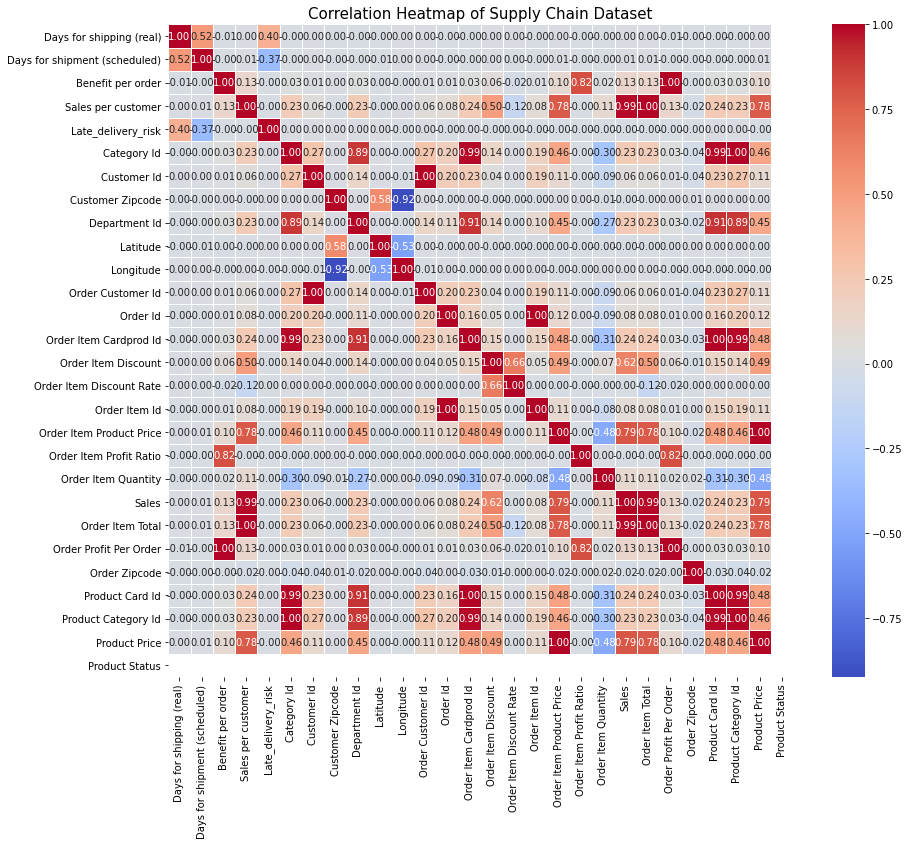

In [29]:
# Select only numerical columns for correlation
numerical_columns = DataCo.select_dtypes(include=['float64', 'int64']).columns

# Calculate the correlation matrix
correlation_matrix = DataCo[numerical_columns].corr()

# Set up the matplotlib figure
plt.figure(figsize=(14, 12))

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=.5)

# Add a title
plt.title('Correlation Heatmap of Supply Chain Dataset', size=15)
plt.savefig('correlation_analysis.png')

In [16]:
print(correlation_matrix)

                               Days for shipping (real)  \
Days for shipping (real)                       1.000000   
Days for shipment (scheduled)                  0.515880   
Benefit per order                             -0.005101   
Sales per customer                             0.001757   
Late_delivery_risk                             0.401415   
Category Id                                   -0.000348   
Customer Id                                    0.003432   
Customer Zipcode                               0.000113   
Department Id                                 -0.001631   
Latitude                                      -0.004073   
Longitude                                      0.003911   
Order Customer Id                              0.003432   
Order Id                                      -0.001711   
Order Item Cardprod Id                        -0.000859   
Order Item Discount                            0.002231   
Order Item Discount Rate                       0.001467 

In [17]:
# Get the pairs of features with correlation > 0.8 or < -0.8
threshold = 0.8
high_corr_pairs = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) > threshold:
            high_corr_pairs.append((correlation_matrix.columns[i], correlation_matrix.index[j], correlation_matrix.iloc[i, j]))

# Convert to DataFrame for better readability
high_corr_df = pd.DataFrame(high_corr_pairs, columns=['Feature 1', 'Feature 2', 'Correlation'])

print(high_corr_df)

                  Feature 1                 Feature 2  Correlation
0             Department Id               Category Id     0.888835
1                 Longitude          Customer Zipcode    -0.923885
2         Order Customer Id               Customer Id     1.000000
3    Order Item Cardprod Id               Category Id     0.991092
4    Order Item Cardprod Id             Department Id     0.906117
5             Order Item Id                  Order Id     0.999623
6   Order Item Profit Ratio         Benefit per order     0.823689
7                     Sales        Sales per customer     0.989744
8          Order Item Total        Sales per customer     1.000000
9          Order Item Total                     Sales     0.989744
10   Order Profit Per Order         Benefit per order     1.000000
11   Order Profit Per Order   Order Item Profit Ratio     0.823689
12          Product Card Id               Category Id     0.991092
13          Product Card Id             Department Id     0.90

In [18]:

# Find the unique features to retain
features_to_drop = set()
for pair in high_corr_pairs:
    feature_1, feature_2 = pair[0], pair[1]
    if feature_1 not in features_to_drop and feature_2 not in features_to_drop:
        # Arbitrarily choose to drop the second feature in the pair
        features_to_drop.add(feature_2)

# Get the remaining features
all_features = set(correlation_matrix.columns)
features_to_retain = list(all_features - features_to_drop)

# Print or use the retained features
print("Features to retain:", features_to_retain)


Features to retain: ['Order Item Total', 'Order Item Id', 'Product Price', 'Order Item Discount Rate', 'Product Status', 'Order Customer Id', 'Order Item Discount', 'Order Item Quantity', 'Days for shipment (scheduled)', 'Longitude', 'Order Profit Per Order', 'Product Category Id', 'Late_delivery_risk', 'Latitude', 'Days for shipping (real)', 'Order Zipcode']


In [19]:
# List of features to retain
features_to_retain = [
    'Order Item Discount Rate', 'Latitude', 'Days for shipment (scheduled)',
    'Order Item Discount', 'Longitude', 'Order Profit Per Order', 'Order Zipcode',
     'Days for shipping (real)', 'Late_delivery_risk',
    'Order Item Quantity', 'Order Item Total', 'Product Price'
]

# Select only the specified features
data_co_reduced = DataCo[features_to_retain]

# Print the first few rows of the reduced dataframe
data_co_reduced.head()


,Order Item Discount Rate,Latitude,Days for shipment (scheduled),Order Item Discount,Longitude,Order Profit Per Order,Order Zipcode,Days for shipping (real),Late_delivery_risk,Order Item Quantity,Order Item Total,Product Price
0,0.04,18.251453,4,13.110000,-66.037056,91.250000,59405.0,3,0,1,314.640015,327.75
1,0.05,18.279451,4,16.389999,-66.037064,-249.089996,59405.0,5,1,1,311.359985,327.75
2,0.06,37.292233,4,18.030001,-121.881279,-247.779999,59405.0,4,0,1,309.720001,327.75
3,0.07,34.125946,4,22.940001,-118.291016,22.860001,59405.0,3,0,1,304.809998,327.75
4,0.09,18.253769,4,29.500000,-66.037048,134.210007,59405.0,2,0,1,298.250000,327.75


In [20]:
data_co_reduced.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 12 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Order Item Discount Rate       180519 non-null  float64
 1   Latitude                       180519 non-null  float64
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Order Item Discount            180519 non-null  float64
 4   Longitude                      180519 non-null  float64
 5   Order Profit Per Order         180519 non-null  float64
 6   Order Zipcode                  180519 non-null  float64
 7   Days for shipping (real)       180519 non-null  int64  
 8   Late_delivery_risk             180519 non-null  int64  
 9   Order Item Quantity            180519 non-null  int64  
 10  Order Item Total               180519 non-null  float64
 11  Product Price                  180519 non-null  float64
dtypes: float64(8), int64(4)
memory

In [21]:
data_co_reduced.isnull().sum()



Order Item Discount Rate         0
Latitude                         0
Days for shipment (scheduled)    0
Order Item Discount              0
Longitude                        0
Order Profit Per Order           0
Order Zipcode                    0
Days for shipping (real)         0
Late_delivery_risk               0
Order Item Quantity              0
Order Item Total                 0
Product Price                    0
dtype: int64

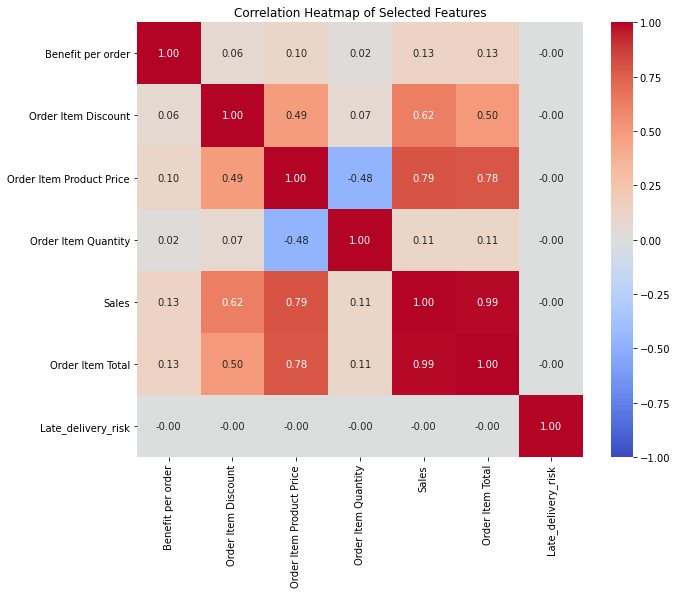

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

# Selecting the relevant features with their correct names
selected_features = [
    'shipping date (DateOrders)',        # Correct name for shipping_date_dateorders
    'Benefit per order',                  # Correct name for benefit_per_order
    'order date (DateOrders)',            # Correct name for order_date_dateorders
    'Order Item Discount',                # Correct name for order_item_discount
    'Order Item Product Price',           # Correct name for order_item_product_price
    'Order Item Quantity',                # Correct name for order_item_quantity
    'Sales',                              # Correct name for sales
    'Order Item Total',                   # Correct name for order_item_total
    'Late_delivery_risk'                  # Correct name for late_delivery_risk
]

# Creating a dataframe with the selected features
correlation_data = DataCo[selected_features]

# Calculating the correlation matrix
correlation_matrix = correlation_data.corr()

# Plotting the correlation heatmap
plt.figure(figsize=(10, 8))
heatmap = sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)

# Adding title to the heatmap
plt.title('Correlation Heatmap of Selected Features')

# Saving the plot as an image
plt.savefig('correlation_heatmap2.png')

# Display the plot
plt.show()


### EDA

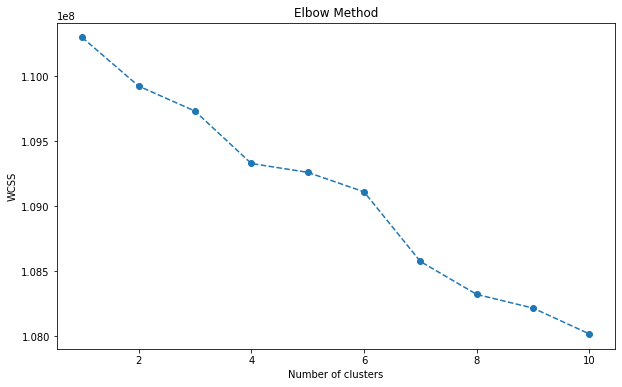

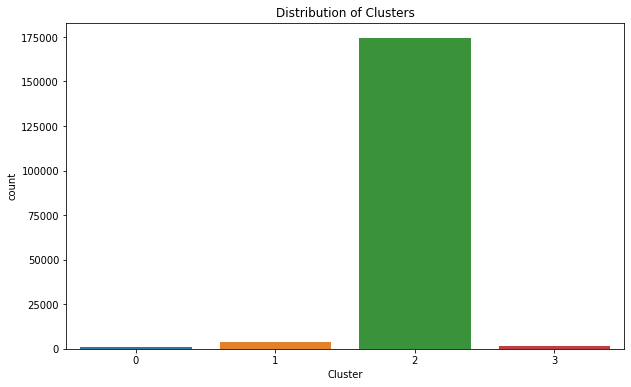

,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Id,Customer Zipcode,Department Id,Latitude,...,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Zipcode,Product Card Id,Product Category Id,Product Price,Product Status
Cluster,,,,,,,,,,,,,,,,,,,,,
0,3.391534,2.919577,24.456751,176.380944,0.519577,32.631746,6295.116402,85027.047619,5.498413,33.561163,...,0.125407,2.080423,196.755496,176.380944,24.456751,58724.843386,709.552381,32.631746,138.954564,0.0
1,3.442469,2.896967,20.461577,180.849547,0.535826,31.314592,6628.479603,18332.669195,5.377092,39.911146,...,0.117325,2.153766,201.934889,180.849547,20.461577,58219.417103,680.947437,31.314592,137.636266,0.0
2,3.498164,2.932150,21.980214,183.170318,0.548689,31.863003,6696.990368,35601.096598,5.445149,29.422384,...,0.120686,2.127118,203.819818,183.170318,21.980214,58867.391601,692.761947,31.863003,141.317903,0.0
3,3.652083,2.995833,23.732805,185.927550,0.552083,31.366667,6439.272917,89107.257639,5.379167,36.156369,...,0.121632,2.152083,207.478921,185.927550,23.732805,59441.016667,681.503472,31.366667,141.945719,0.0


In [23]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
# Selecting relevant features
features = ['Customer City', 'Customer Country', 'Customer Segment', 'Customer State', 'Customer Zipcode']
data_selected = DataCo[features]

# Encoding categorical variables
data_encoded = pd.get_dummies(data_selected, drop_first=True)

# Scaling the features
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data_encoded)

# Finding the optimal number of clusters using the Elbow Method
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(data_scaled)
    wcss.append(kmeans.inertia_)

# Plotting the results
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

# Applying KMeans with the optimal number of clusters (e.g., 4)
kmeans = KMeans(n_clusters=4, random_state=42)
DataCo['Cluster'] = kmeans.fit_predict(data_scaled)

# Displaying the first few rows of the dataframe with the cluster labels
DataCo.head()

# Plotting the distribution of clusters
plt.figure(figsize=(10, 6))
sns.countplot(x='Cluster', data=DataCo)
plt.title('Distribution of Clusters')
plt.show()

# Analyzing the characteristics of each cluster
cluster_analysis = DataCo.groupby('Cluster').mean()
cluster_analysis


In [24]:
cluster_analysis

,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Id,Customer Zipcode,Department Id,Latitude,...,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Zipcode,Product Card Id,Product Category Id,Product Price,Product Status
Cluster,,,,,,,,,,,,,,,,,,,,,
0,3.391534,2.919577,24.456751,176.380944,0.519577,32.631746,6295.116402,85027.047619,5.498413,33.561163,...,0.125407,2.080423,196.755496,176.380944,24.456751,58724.843386,709.552381,32.631746,138.954564,0.0
1,3.442469,2.896967,20.461577,180.849547,0.535826,31.314592,6628.479603,18332.669195,5.377092,39.911146,...,0.117325,2.153766,201.934889,180.849547,20.461577,58219.417103,680.947437,31.314592,137.636266,0.0
2,3.498164,2.932150,21.980214,183.170318,0.548689,31.863003,6696.990368,35601.096598,5.445149,29.422384,...,0.120686,2.127118,203.819818,183.170318,21.980214,58867.391601,692.761947,31.863003,141.317903,0.0
3,3.652083,2.995833,23.732805,185.927550,0.552083,31.366667,6439.272917,89107.257639,5.379167,36.156369,...,0.121632,2.152083,207.478921,185.927550,23.732805,59441.016667,681.503472,31.366667,141.945719,0.0


In [25]:
DataCo['Customer Segment'].value_counts()

Consumer       93504
Corporate      54789
Home Office    32226
Name: Customer Segment, dtype: int64

In [27]:
DataCo.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 55 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

In [9]:
# Grouping the data by Customer Segment and calculating total sales
grouped_data = DataCo.groupby('Customer Segment')['Sales'].sum().astype(int).reset_index()

# Display the grouped data
print(grouped_data)


  Customer Segment     Sales
0         Consumer  19095790
1        Corporate  11168406
2      Home Office   6520538


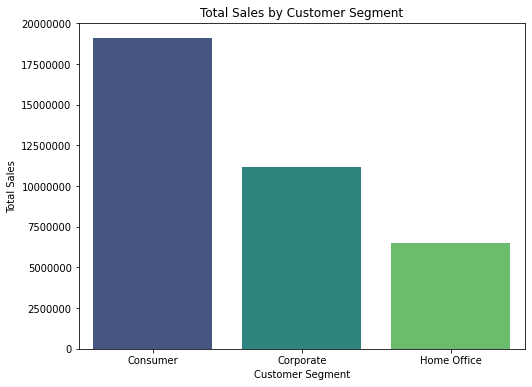

In [13]:
from matplotlib.ticker import ScalarFormatter
# Plotting the histogram
plt.figure(figsize=(8, 6))
sns.barplot(x='Customer Segment', y='Sales', data=grouped_data, palette='viridis')
formatter = ScalarFormatter(useOffset=False)
formatter.set_scientific(False)
plt.gca().yaxis.set_major_formatter(formatter)
# Adding labels and title
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')
plt.title('Total Sales by Customer Segment')

# Display the plot
plt.show()


{'encoding': 'ISO-8859-1', 'confidence': 0.73, 'language': ''}
       Type  Days for shipping (real)  Days for shipment (scheduled)  \
0     DEBIT                         3                              4   
1  TRANSFER                         5                              4   
2      CASH                         4                              4   
3     DEBIT                         3                              4   
4   PAYMENT                         2                              4   

   Benefit per order  Sales per customer   Delivery Status  \
0          91.250000          314.640015  Advance shipping   
1        -249.089996          311.359985     Late delivery   
2        -247.779999          309.720001  Shipping on time   
3          22.860001          304.809998  Advance shipping   
4         134.210007          298.250000  Advance shipping   

   Late_delivery_risk  Category Id   Category Name Customer City  ...  \
0                   0           73  Sporting Goods        

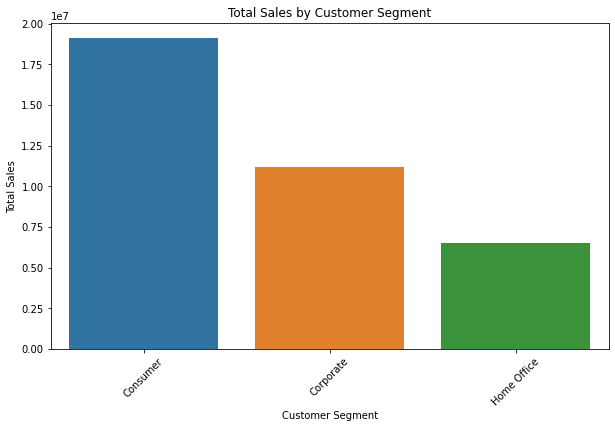

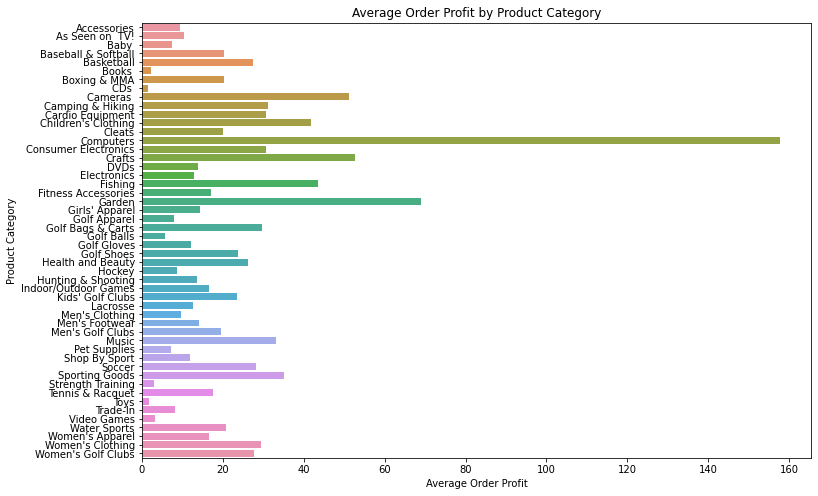

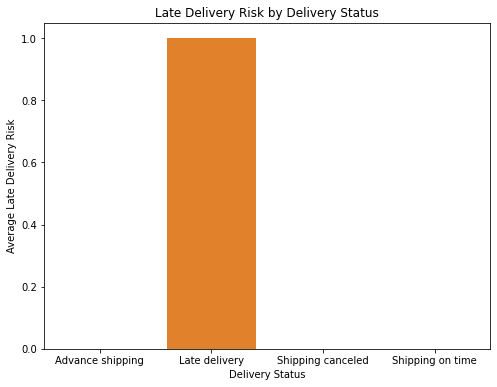

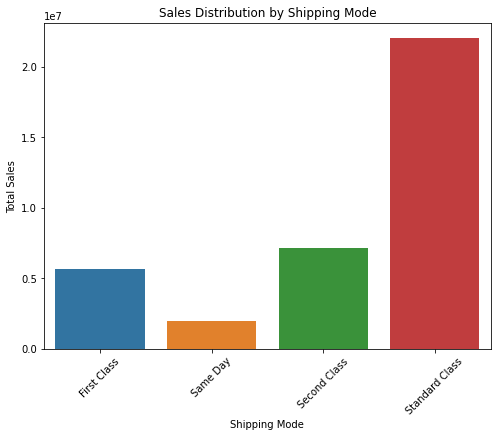

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
import chardet

# Read a sample of the file
with open('DataCoSupplyChainDataset.csv', 'rb') as f:
    result = chardet.detect(f.read(100000))  # Read the first 10,000 bytes
    print(result)

# Use the detected encoding to read the file
data = pd.read_csv(r'DataCoSupplyChainDataset.csv', encoding=result['encoding'])

# Sample dataset display
print(data.head())

# Basic statistics for numerical columns
summary_stats = data.describe()
print(summary_stats)

# Calculation: Total sales by customer segment
sales_by_segment = data.groupby('Customer Segment')['Sales'].sum().reset_index()

# Visualization: Total sales by customer segment
plt.figure(figsize=(10, 6))
sns.barplot(x='Customer Segment', y='Sales', data=sales_by_segment)
plt.title('Total Sales by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

# Calculation: Average order profit by product category
avg_profit_by_category = data.groupby('Category Name')['Order Profit Per Order'].mean().reset_index()

# Visualization: Average order profit by product category
plt.figure(figsize=(12, 8))
sns.barplot(x='Order Profit Per Order', y='Category Name', data=avg_profit_by_category)
plt.title('Average Order Profit by Product Category')
plt.xlabel('Average Order Profit')
plt.ylabel('Product Category')
plt.show()

# Calculation: Late delivery risk by delivery status
late_delivery_risk = data.groupby('Delivery Status')['Late_delivery_risk'].mean().reset_index()

# Visualization: Late delivery risk by delivery status
plt.figure(figsize=(8, 6))
sns.barplot(x='Delivery Status', y='Late_delivery_risk', data=late_delivery_risk)
plt.title('Late Delivery Risk by Delivery Status')
plt.xlabel('Delivery Status')
plt.ylabel('Average Late Delivery Risk')
plt.show()

# Calculation: Sales distribution by shipping mode
sales_by_shipping_mode = data.groupby('Shipping Mode')['Sales'].sum().reset_index()

# Visualization: Sales distribution by shipping mode
plt.figure(figsize=(8, 6))
sns.barplot(x='Shipping Mode', y='Sales', data=sales_by_shipping_mode)
plt.title('Sales Distribution by Shipping Mode')
plt.xlabel('Shipping Mode')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

# Export summary statistics to CSV
summary_stats.to_csv('summary_statistics.csv', index=False)


<AxesSubplot: xlabel='Customer Segment', ylabel='Sales'>

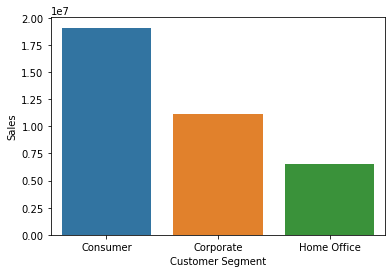

In [3]:
sales_by_segment = data.groupby('Customer Segment')['Sales'].sum().reset_index()
sns.barplot(x='Customer Segment', y='Sales', data=sales_by_segment)


<AxesSubplot: xlabel='Order Profit Per Order', ylabel='Category Name'>

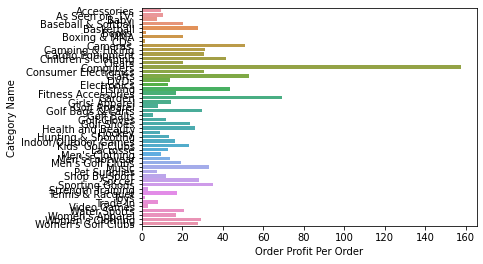

In [4]:
avg_profit_by_category = data.groupby('Category Name')['Order Profit Per Order'].mean().reset_index()
sns.barplot(x='Order Profit Per Order', y='Category Name', data=avg_profit_by_category)


In [15]:
# Grouping the data by Customer Segment and calculating total sales
grouped_data = DataCo.groupby('Customer Segment')['Benefit per order'].sum().astype(int).reset_index()

# Display the grouped data
print(grouped_data)


  Customer Segment  Benefit per order
0         Consumer            2073487
1        Corporate            1202574
2      Home Office             690840


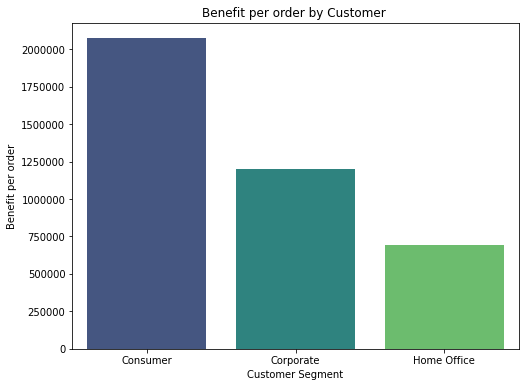

In [17]:
from matplotlib.ticker import ScalarFormatter
# Plotting the histogram
plt.figure(figsize=(8, 6))
sns.barplot(x='Customer Segment', y='Benefit per order', data=grouped_data, palette='viridis')
formatter = ScalarFormatter(useOffset=False)
formatter.set_scientific(False)
plt.gca().yaxis.set_major_formatter(formatter)
# Adding labels and title
plt.xlabel('Customer Segment')
plt.ylabel('Benefit per order')
plt.title('Benefit per order by Customer ')

# Display the plot
plt.show()


In [18]:
# Grouping the data by Customer Segment and calculating total sales
grouped_data = DataCo.groupby('Customer Segment')['Sales per customer'].sum().astype(int).reset_index()

# Display the grouped data
print(grouped_data)


  Customer Segment  Sales per customer
0         Consumer            17164278
1        Corporate            10030649
2      Home Office             5859474


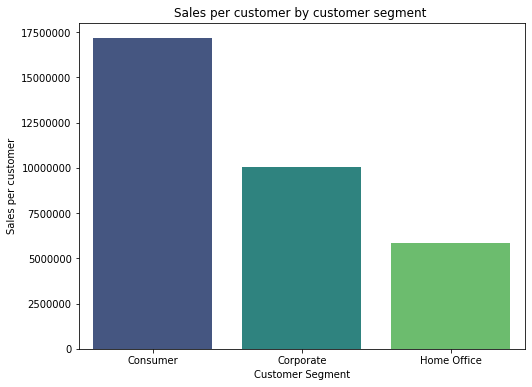

In [19]:
from matplotlib.ticker import ScalarFormatter
# Plotting the histogram
plt.figure(figsize=(8, 6))
sns.barplot(x='Customer Segment', y='Sales per customer', data=grouped_data, palette='viridis')
formatter = ScalarFormatter(useOffset=False)
formatter.set_scientific(False)
plt.gca().yaxis.set_major_formatter(formatter)
# Adding labels and title
plt.xlabel('Customer Segment')
plt.ylabel('Sales per customer')
plt.title('Sales per customer by customer segment ')

# Display the plot
plt.show()


In [20]:
# Grouping the data by Customer Segment and calculating total sales
grouped_data = DataCo.groupby('Customer Segment')['Order Profit Per Order'].sum().astype(int).reset_index()

# Display the grouped data
print(grouped_data)


  Customer Segment  Order Profit Per Order
0         Consumer                 2073487
1        Corporate                 1202574
2      Home Office                  690840


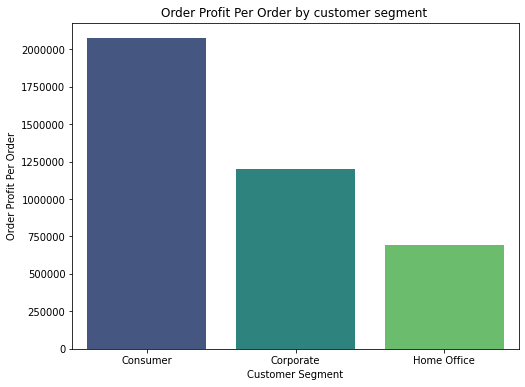

In [21]:
from matplotlib.ticker import ScalarFormatter
# Plotting the histogram
plt.figure(figsize=(8, 6))
sns.barplot(x='Customer Segment', y='Order Profit Per Order', data=grouped_data, palette='viridis')
formatter = ScalarFormatter(useOffset=False)
formatter.set_scientific(False)
plt.gca().yaxis.set_major_formatter(formatter)
# Adding labels and title
plt.xlabel('Customer Segment')
plt.ylabel('Order Profit Per Order')
plt.title('Order Profit Per Order by customer segment ')

# Display the plot
plt.show()


In [ ]:
Order Item Quantity

In [22]:
# Grouping the data by Customer Segment and calculating total sales
grouped_data = DataCo.groupby('Customer Segment')['Order Item Quantity'].sum().astype(int).reset_index()

# Display the grouped data
print(grouped_data)


  Customer Segment  Order Item Quantity
0         Consumer               199234
1        Corporate               116560
2      Home Office                68285


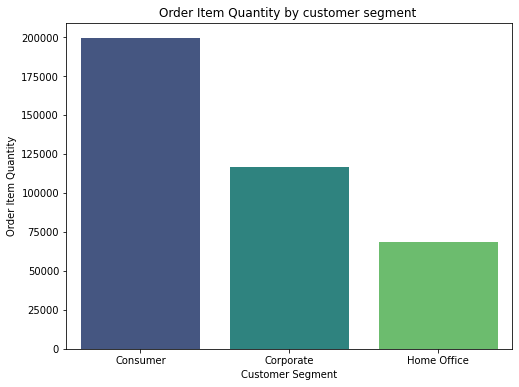

In [23]:
from matplotlib.ticker import ScalarFormatter
# Plotting the histogram
plt.figure(figsize=(8, 6))
sns.barplot(x='Customer Segment', y='Order Item Quantity', data=grouped_data, palette='viridis')
formatter = ScalarFormatter(useOffset=False)
formatter.set_scientific(False)
plt.gca().yaxis.set_major_formatter(formatter)
# Adding labels and title
plt.xlabel('Customer Segment')
plt.ylabel('Order Item Quantity')
plt.title('Order Item Quantity by customer segment ')

# Display the plot
plt.show()


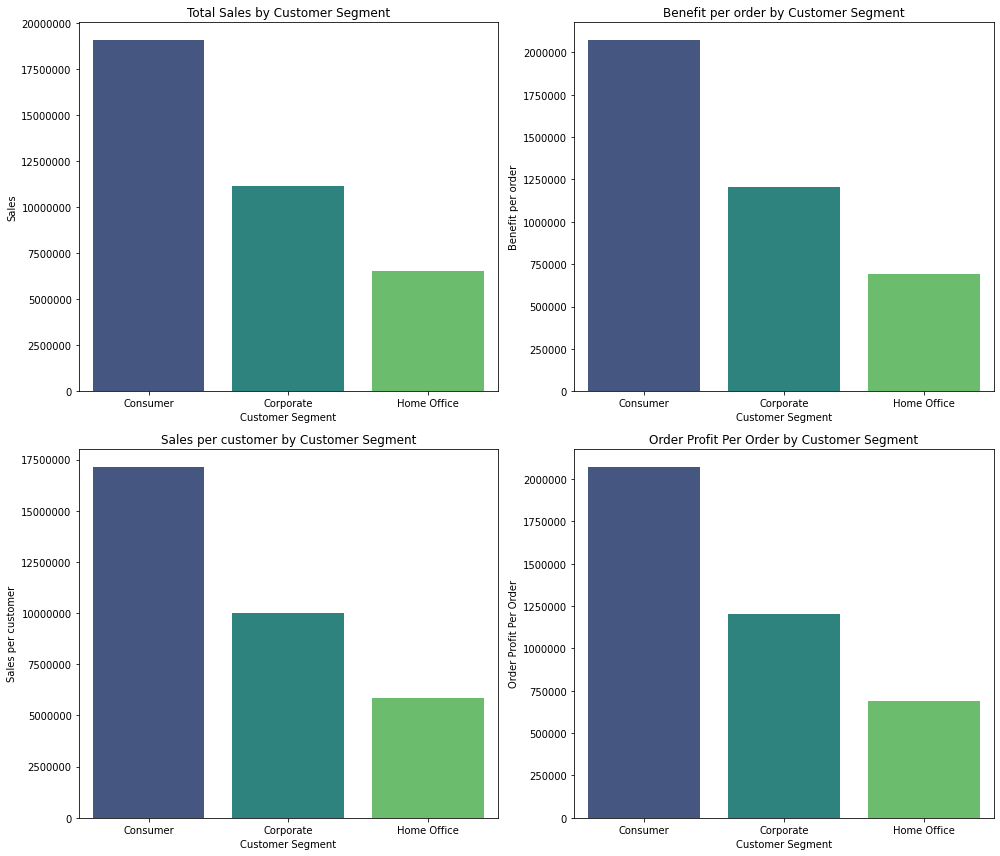

In [11]:

# Group data for each feature
grouped_sales = DataCo.groupby('Customer Segment')['Sales'].sum().reset_index()
grouped_benefit_per_order = DataCo.groupby('Customer Segment')['Benefit per order'].sum().reset_index()
grouped_sales_per_customer = DataCo.groupby('Customer Segment')['Sales per customer'].sum().reset_index()
grouped_order_profit_per_order = DataCo.groupby('Customer Segment')['Order Profit Per Order'].sum().reset_index()

# Set up the figure and axes
fig, axes = plt.subplots(2, 2, figsize=(14, 12))  # Adjust the figsize as needed
axes = axes.flatten()  # Flatten the array of axes for easy indexing

# List of plots data
plots = [
    (grouped_sales, 'Sales', 'Total Sales by Customer Segment'),
    (grouped_benefit_per_order, 'Benefit per order', 'Benefit per order by Customer Segment'),
    (grouped_sales_per_customer, 'Sales per customer', 'Sales per customer by Customer Segment'),
    (grouped_order_profit_per_order, 'Order Profit Per Order', 'Order Profit Per Order by Customer Segment')
]

# Plotting each subplot
for ax, (data, y, title) in zip(axes, plots):
    sns.barplot(x='Customer Segment', y=y, data=data, palette='viridis', ax=ax)
    formatter = ScalarFormatter(useOffset=False)
    formatter.set_scientific(False)
    ax.yaxis.set_major_formatter(formatter)
    ax.set_xlabel('Customer Segment')
    ax.set_ylabel(y)
    ax.set_title(title)

# Adjust layout and save the figure
plt.tight_layout()
plt.savefig('Customer_Segment_Analysis.png')  # Save the figure as an image
plt.show()


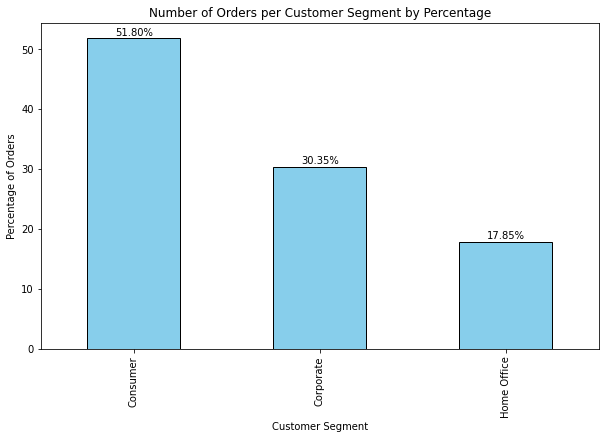

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming you have already loaded your DataCo dataset into a DataFrame called df
# df = pd.read_csv('your_dataset.csv')

# Calculate the number of orders per customer segment
orders_per_segment = DataCo['Customer Segment'].value_counts()

# Convert to percentage
orders_per_segment_percentage = (orders_per_segment / orders_per_segment.sum()) * 100

# Plotting the bar plot
plt.figure(figsize=(10, 6))
orders_per_segment_percentage.plot(kind='bar', color='skyblue', edgecolor='black')

# Adding labels and title
plt.title('Number of Orders per Customer Segment by Percentage')
plt.xlabel('Customer Segment')
plt.ylabel('Percentage of Orders')

# Adding percentage labels on top of the bars
for index, value in enumerate(orders_per_segment_percentage):
    plt.text(index, value + 0.5, f'{value:.2f}%', ha='center')

# Show plot
plt.show()


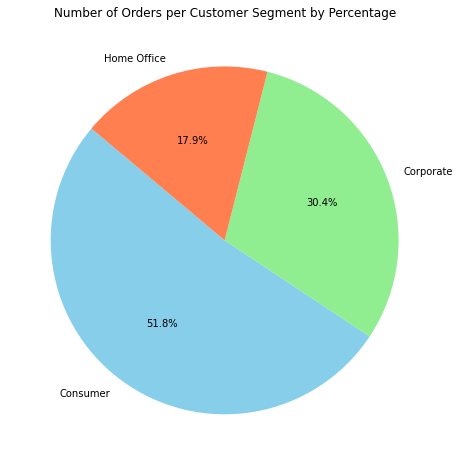

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming you have already loaded your DataCo dataset into a DataFrame called df
# df = pd.read_csv('your_dataset.csv')

# Calculate the number of orders per customer segment
orders_per_segment = DataCo['Customer Segment'].value_counts()

# Convert to percentage
orders_per_segment_percentage = (orders_per_segment / orders_per_segment.sum()) * 100

# Plotting the pie chart
plt.figure(figsize=(8, 8))
plt.pie(orders_per_segment_percentage, labels=orders_per_segment_percentage.index, autopct='%1.1f%%', startangle=140, colors=['skyblue', 'lightgreen', 'coral'])

# Adding title
plt.title('Number of Orders per Customer Segment by Percentage')

# Show plot
plt.show()


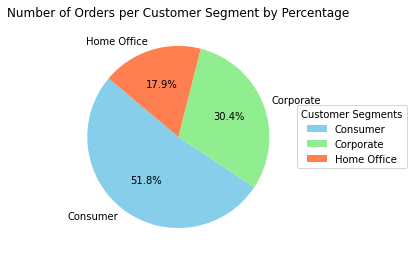

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# Calculate the number of orders per customer segment
orders_per_segment = DataCo['Customer Segment'].value_counts()

# Convert to percentage
orders_per_segment_percentage = (orders_per_segment / orders_per_segment.sum()) * 100

# Plotting the pie chart
plt.figure(figsize=(5, 5))
wedges, texts, autotexts = plt.pie(
    orders_per_segment_percentage, 
    labels=orders_per_segment_percentage.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=['skyblue', 'lightgreen', 'coral']
)

# Adding title
plt.title('Number of Orders per Customer Segment by Percentage')

# Adding legend
plt.legend(wedges, orders_per_segment_percentage.index, title="Customer Segments", loc="center left", bbox_to_anchor=(1, 0, 0.5, 1))

# Adjust layout to ensure legend is included in the saved figure
plt.tight_layout()

# Save the figure
plt.savefig('Orders_Per_Customer_Segment.png', bbox_inches='tight')  # Save the figure with tight bounding box

# Show plot
plt.show()


         Market     Sales
0        Africa   2294452
1        Europe  10872396
2         LATAM  10277612
3  Pacific Asia   8273743
4          USCA   5066528


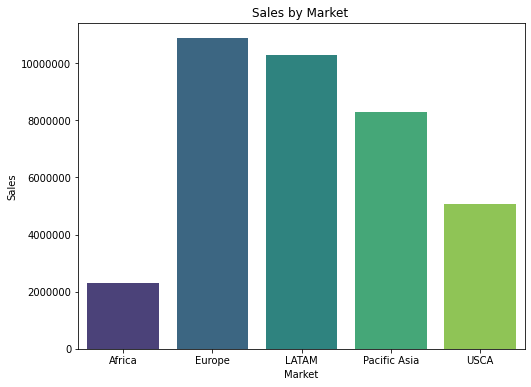

In [35]:
# Grouping the data by Customer Segment and calculating total sales
grouped_data = DataCo.groupby('Market')['Sales'].sum().astype(int).reset_index()

# Display the grouped data
print(grouped_data)
from matplotlib.ticker import ScalarFormatter
# Plotting the histogram
plt.figure(figsize=(8, 6))
sns.barplot(x='Market', y='Sales', data=grouped_data, palette='viridis')
formatter = ScalarFormatter(useOffset=False)
formatter.set_scientific(False)
plt.gca().yaxis.set_major_formatter(formatter)
# Adding labels and title
plt.xlabel('Market')
plt.ylabel('Sales')
plt.title('Sales by Market ')

# Display the plot
plt.show()



         Market  Benefit per order
0        Africa             252071
1        Europe            1169442
2         LATAM            1123321
3  Pacific Asia             857753
4          USCA             564313


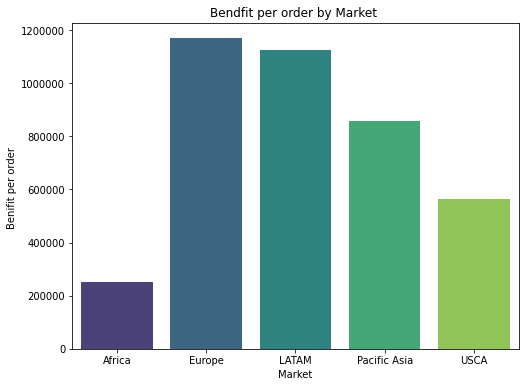

In [37]:
# Grouping the data by Customer Segment and calculating total sales
grouped_data = DataCo.groupby('Market')['Benefit per order'].sum().astype(int).reset_index()

# Display the grouped data
print(grouped_data)
from matplotlib.ticker import ScalarFormatter
# Plotting the histogram
plt.figure(figsize=(8, 6))
sns.barplot(x='Market', y='Benefit per order', data=grouped_data, palette='viridis')
formatter = ScalarFormatter(useOffset=False)
formatter.set_scientific(False)
plt.gca().yaxis.set_major_formatter(formatter)
# Adding labels and title
plt.xlabel('Market')
plt.ylabel('Benifit per order ')
plt.title('Bendfit per order by Market ')

# Display the plot
plt.show()



         Market  Order Profit Per Order
0        Africa                  252071
1        Europe                 1169442
2         LATAM                 1123321
3  Pacific Asia                  857753
4          USCA                  564313


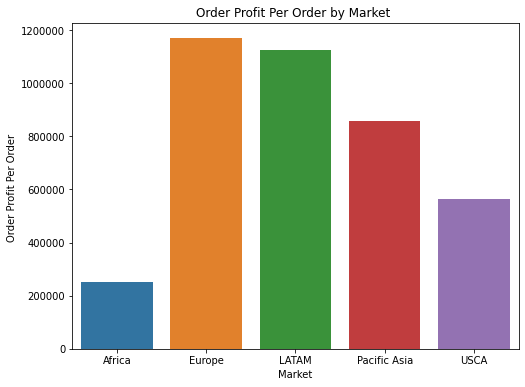

In [41]:
# Grouping the data by Customer Segment and calculating total sales
grouped_data = DataCo.groupby('Market')['Order Profit Per Order'].sum().astype(int).reset_index()

# Display the grouped data
print(grouped_data)
from matplotlib.ticker import ScalarFormatter
# Plotting the histogram
plt.figure(figsize=(8, 6))
sns.barplot(x='Market', y='Order Profit Per Order', data=grouped_data, palette='viridis')
formatter = ScalarFormatter(useOffset=False)
formatter.set_scientific(False)
plt.gca().yaxis.set_major_formatter(formatter)
# Adding labels and title
plt.xlabel('Market')
plt.ylabel('Order Profit Per Order ')
plt.title('Order Profit Per Order by Market ')

# Display the plot
plt.show()



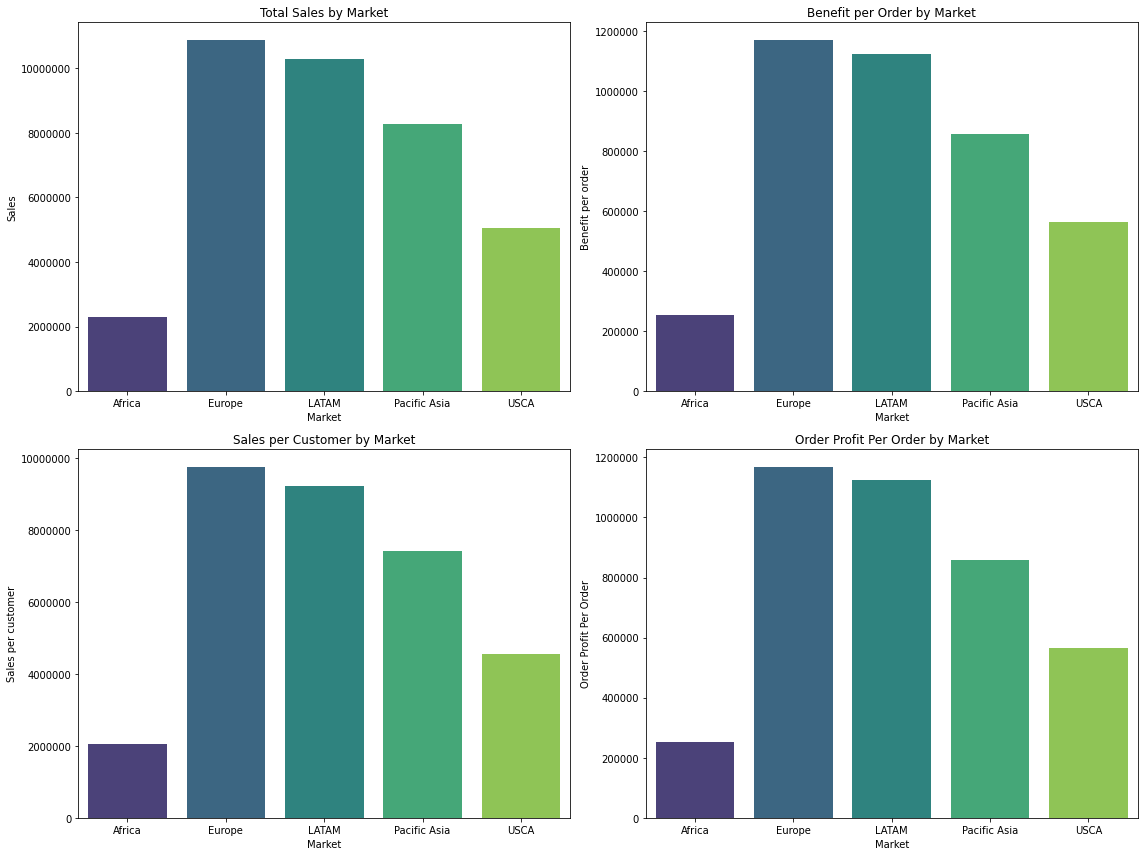

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import ScalarFormatter

# Define a function to plot bar charts for different metrics
def plot_bar(ax, data, y, title, ylabel):
    sns.barplot(x='Market', y=y, data=data, palette='viridis', ax=ax)
    formatter = ScalarFormatter(useOffset=False)
    formatter.set_scientific(False)
    ax.yaxis.set_major_formatter(formatter)
    ax.set_xlabel('Market')
    ax.set_ylabel(ylabel)
    ax.set_title(title)

# Group data and plot
fig, axes = plt.subplots(2, 2, figsize=(16, 12))  # Adjust size as needed
axes = axes.flatten()  # Flatten the array of axes for easy indexing

# Group data and plot each metric
metrics = [
    ('Sales', 'Total Sales by Market', 'Sales'),
    ('Benefit per order', 'Benefit per Order by Market', 'Benefit per order'),
    ('Sales per customer', 'Sales per Customer by Market', 'Sales per customer'),
    ('Order Profit Per Order', 'Order Profit Per Order by Market', 'Order Profit Per Order')
]

for ax, (metric, title, ylabel) in zip(axes, metrics):
    grouped_data = DataCo.groupby('Market')[metric].sum().astype(int).reset_index()
    plot_bar(ax, grouped_data, metric, title, ylabel)

# Remove any empty subplot (if there's an odd number of plots)
if len(metrics) < len(axes):
    fig.delaxes(axes[-1])

# Adjust layout and save the figure
plt.tight_layout()
plt.savefig('Market_Analysis.png', bbox_inches='tight')  # Save the figure
plt.show()


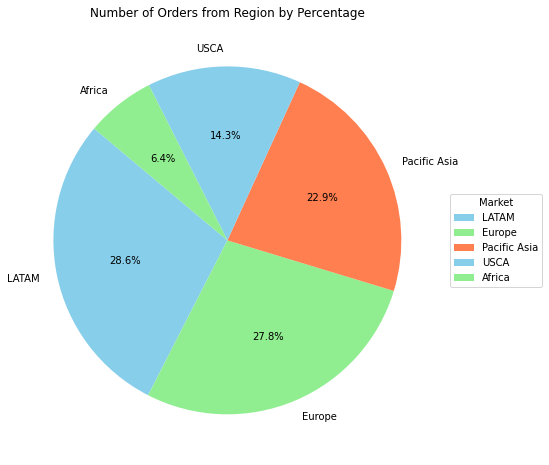

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming you have already loaded your DataCo dataset into a DataFrame called DataCo
# DataCo = pd.read_csv('your_dataset.csv')

# Calculate the number of orders per market
orders_per_segment = DataCo['Market'].value_counts()

# Convert to percentage
orders_per_segment_percentage = (orders_per_segment / orders_per_segment.sum()) * 100

# Plotting the pie chart
fig, ax = plt.subplots(figsize=(8, 8))  # Create a figure and axis

wedges, texts, autotexts = ax.pie(
    orders_per_segment_percentage,
    labels=orders_per_segment_percentage.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['skyblue', 'lightgreen', 'coral']
)

# Adding title
ax.set_title('Number of Orders from Region by Percentage')

# Adding legend
ax.legend(
    wedges,
    orders_per_segment_percentage.index,
    title="Market",
    loc="center left",
    bbox_to_anchor=(1, 0, 0.5, 1)
)

# Save the figure
plt.savefig('Orders_Per_Market_Pie_Chart.png', bbox_inches='tight')  # Save the figure as an image

# Show plot
plt.show()


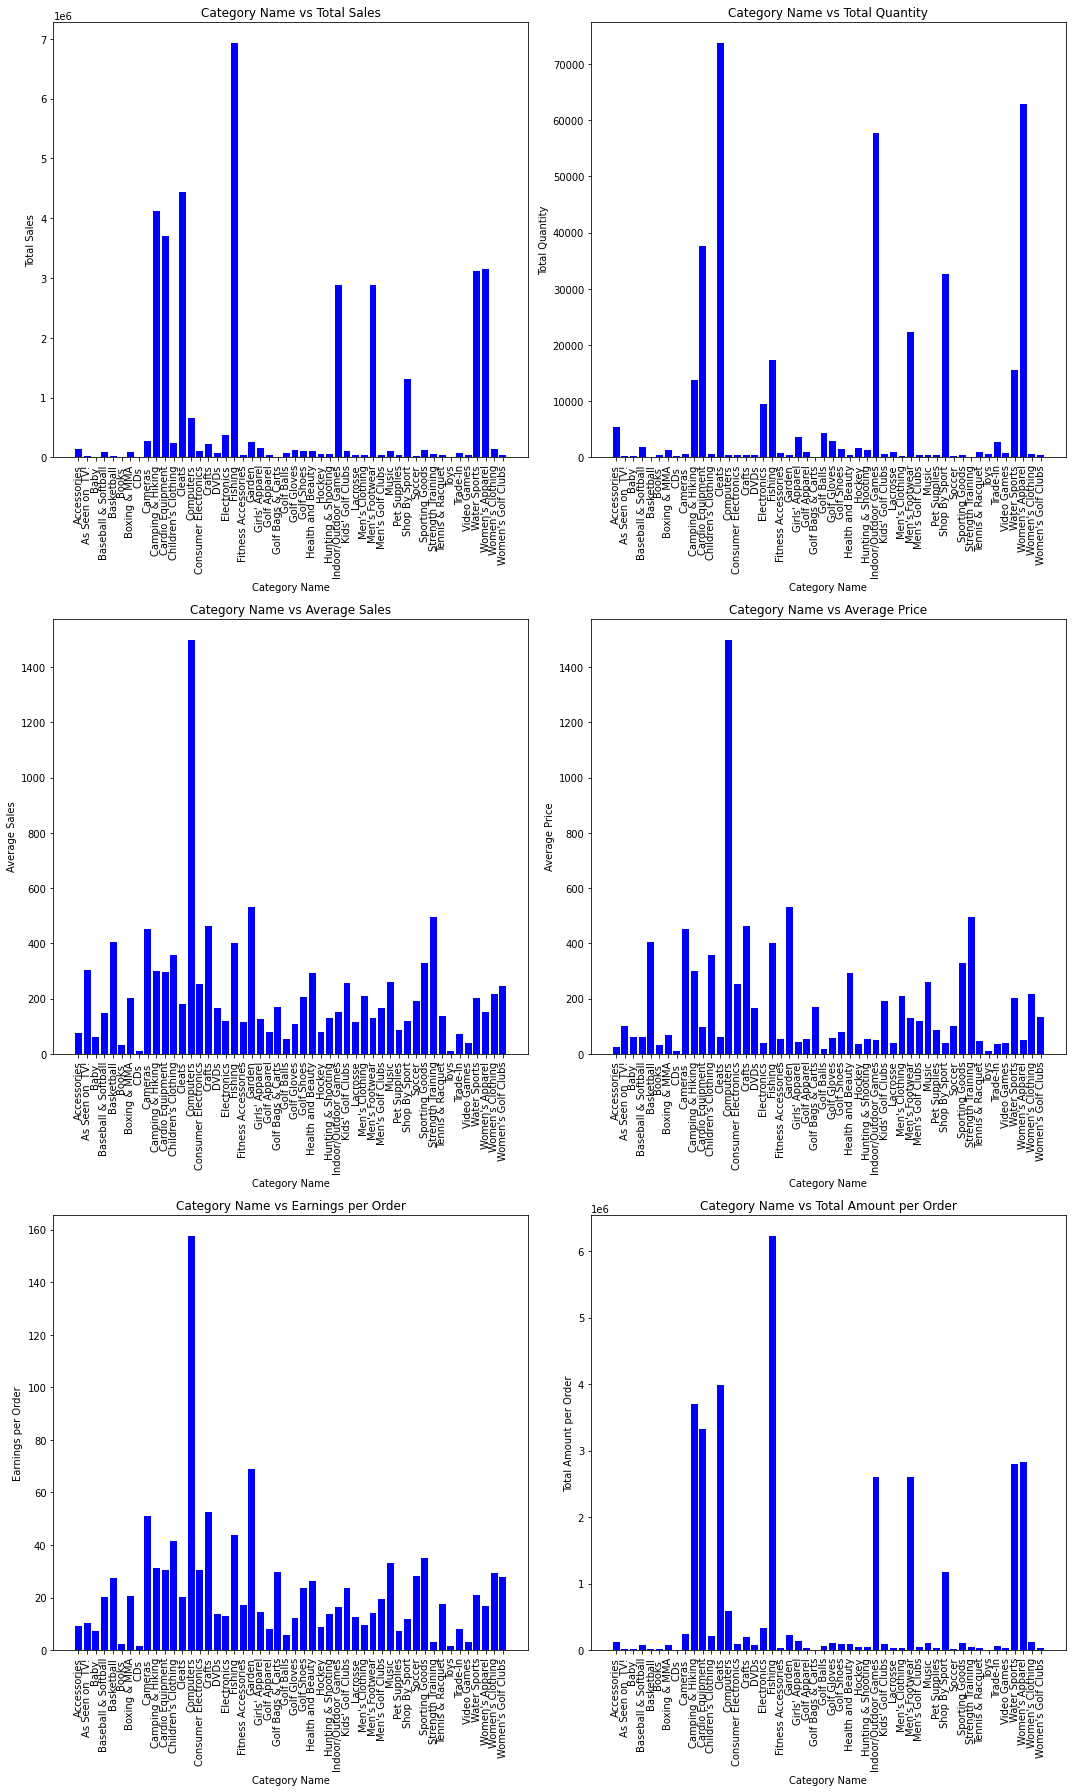

In [44]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming you have already loaded your DataCo dataset into a DataFrame called df
# df = pd.read_csv('your_dataset.csv')

# Group by 'Category Name'
grouped = DataCo.groupby('Category Name').agg({
    'Sales': ['sum', 'mean'],
    'Order Item Quantity': 'sum',
    'Product Price': 'mean',
    'Order Profit Per Order': 'mean',
    'Order Item Total': 'sum'
})

# Rename columns for easier access
grouped.columns = ['Total Sales', 'Average Sales', 'Total Quantity', 'Average Price', 'Earnings per Order', 'Total Amount per Order']

# Plotting histograms
metrics = ['Total Sales', 'Total Quantity', 'Average Sales', 'Average Price', 'Earnings per Order', 'Total Amount per Order']
colors = ['skyblue', 'lightgreen', 'coral', 'lightpink', 'lightgrey', 'lightblue']

plt.figure(figsize=(15, 25))

for i, metric in enumerate(metrics):
    plt.subplot(3, 2, i + 1)
    plt.bar(grouped.index, grouped[metric], color='blue')
    plt.title(f'Category Name vs {metric}')
    plt.xlabel('Category Name')
    plt.ylabel(metric)
    plt.xticks(rotation=90)  # Rotate x-axis labels for better readability

plt.tight_layout()
plt.show()


In [45]:
DataCo['Category Name'].value_counts()

Cleats                  24551
Men's Footwear          22246
Women's Apparel         21035
Indoor/Outdoor Games    19298
Fishing                 17325
Water Sports            15540
Camping & Hiking        13729
Cardio Equipment        12487
Shop By Sport           10984
Electronics              3156
Accessories              1780
Golf Balls               1475
Girls' Apparel           1201
Golf Gloves              1070
Trade-In                  974
Video Games               838
Children's Clothing       652
Women's Clothing          650
Baseball & Softball       632
Hockey                    614
Cameras                   592
Toys                      529
Golf Shoes                524
Pet Supplies              492
Crafts                    484
Garden                    484
DVDs                      483
Computers                 442
Golf Apparel              441
Hunting & Shooting        440
Music                     434
Consumer Electronics      431
Boxing & MMA              423
Books     

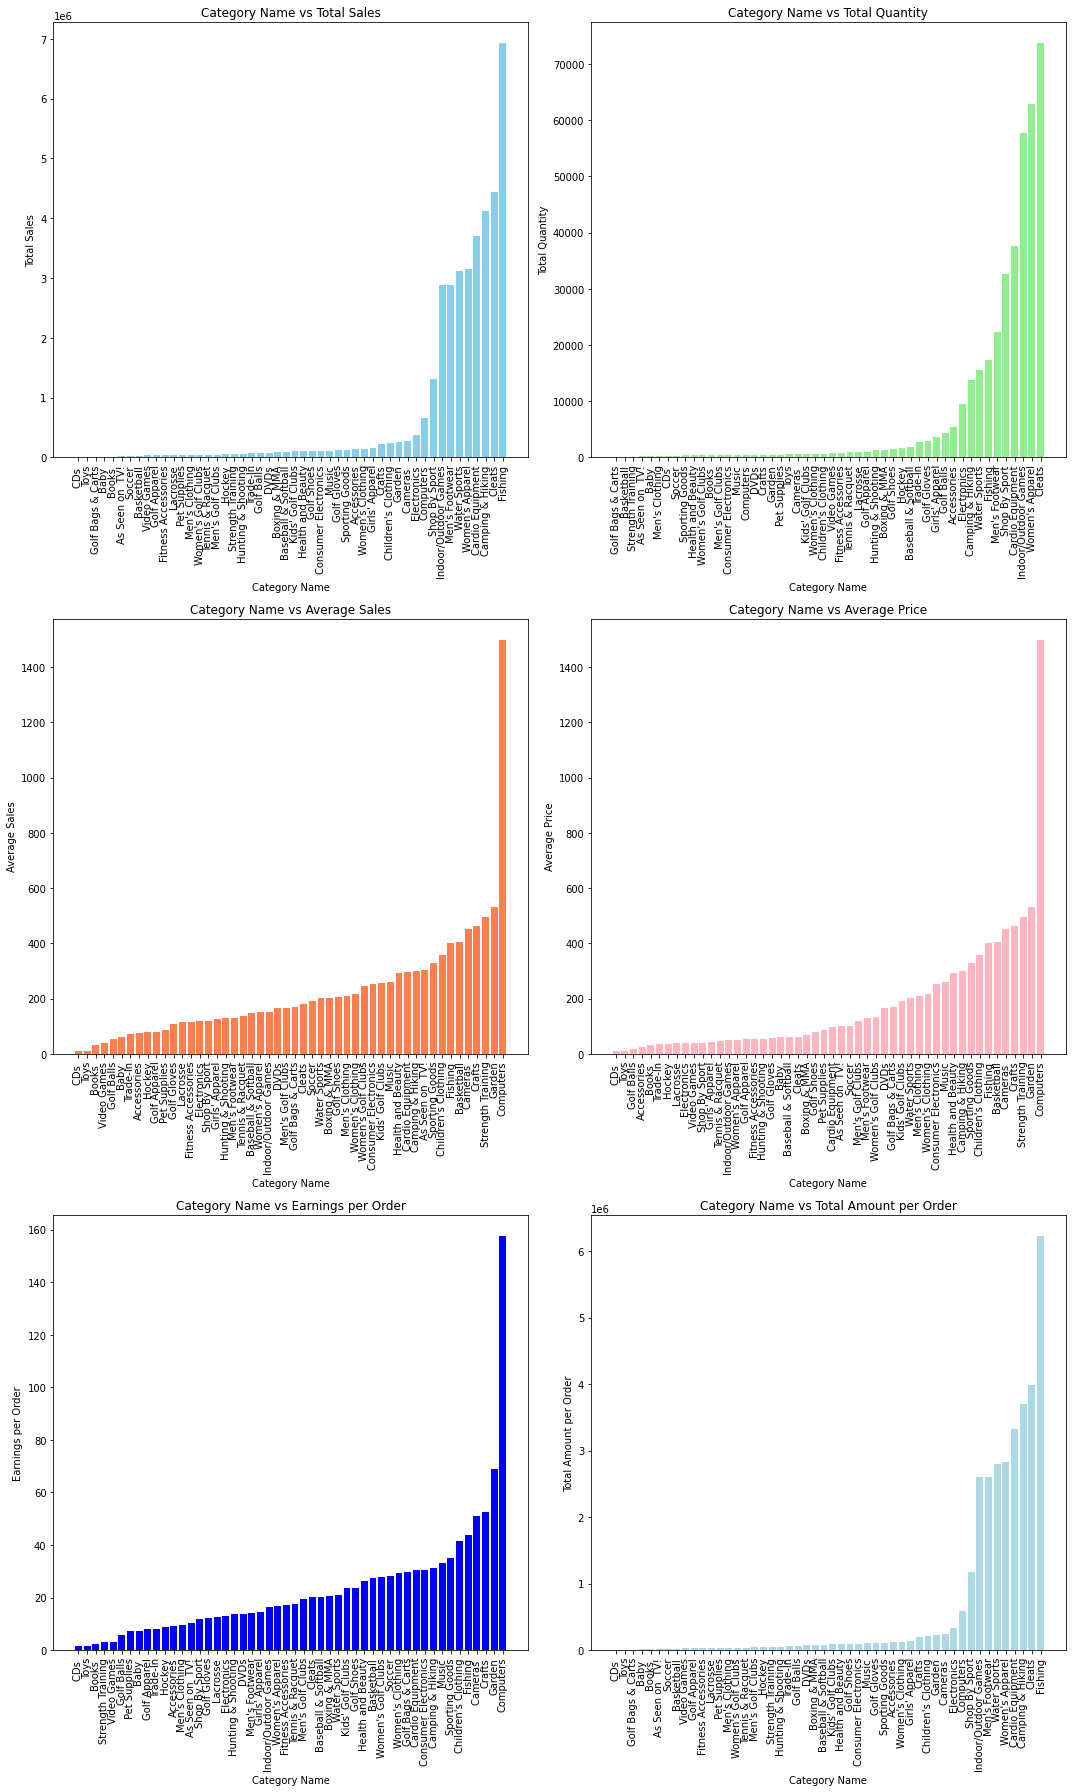

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming you have already loaded your DataCo dataset into a DataFrame called df
# df = pd.read_csv('your_dataset.csv')

# Group by 'Category Name'
grouped = DataCo.groupby('Category Name').agg({
    'Sales': ['sum', 'mean'],
    'Order Item Quantity': 'sum',
    'Product Price': 'mean',
    'Order Profit Per Order': 'mean',
    'Order Item Total': 'sum'
})

# Rename columns for easier access
grouped.columns = ['Total Sales', 'Average Sales', 'Total Quantity', 'Average Price', 'Earnings per Order', 'Total Amount per Order']

# Function to plot sorted histogram
def plot_sorted_histogram(grouped_data, metric, color, ax):
    sorted_data = grouped_data.sort_values(by=metric)
    ax.bar(sorted_data.index, sorted_data[metric], color=color)
    ax.set_title(f'Category Name vs {metric}')
    ax.set_xlabel('Category Name')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=90)  # Rotate x-axis labels for better readability

# Plotting histograms
metrics = ['Total Sales', 'Total Quantity', 'Average Sales', 'Average Price', 'Earnings per Order', 'Total Amount per Order']
colors = ['skyblue', 'lightgreen', 'coral', 'lightpink', 'blue', 'lightblue']

fig, axes = plt.subplots(3, 2, figsize=(15, 25))

for i, (metric, color) in enumerate(zip(metrics, colors)):
    ax = axes[i // 2, i % 2]
    plot_sorted_histogram(grouped, metric, color, ax)

plt.tight_layout()
plt.savefig('Product Category Analyis.png', bbox_inches='tight')  # Save the figure
plt.show()


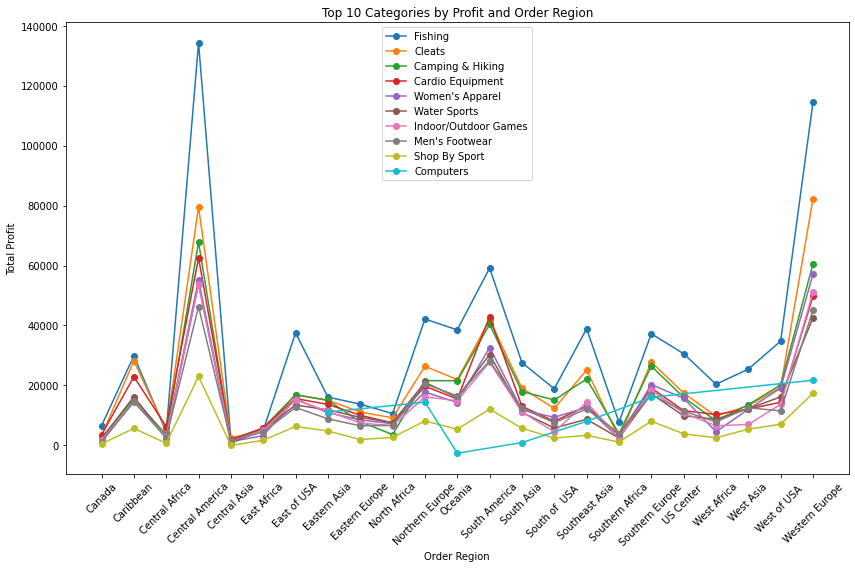

In [53]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming DataCo is your DataFrame
# Group by Category Name and sum the Profit
category_profit = DataCo.groupby('Category Name')['Order Profit Per Order'].sum()

# Get top 10 categories by profit
top_10_categories = category_profit.nlargest(10).index.tolist()

# Filter the DataFrame for only these top categories
top_categories_data = DataCo[DataCo['Category Name'].isin(top_10_categories)]

# Group by Category Name and Order Region, summing the profit
category_region_profit = top_categories_data.groupby(['Category Name', 'Order Region'])['Order Profit Per Order'].sum().reset_index()

# Initialize a figure and axes
plt.figure(figsize=(12, 8))

# Plotting each category with a different color
for category in top_10_categories:
    category_data = category_region_profit[category_region_profit['Category Name'] == category]
    plt.plot(category_data['Order Region'], category_data['Order Profit Per Order'], marker='o', label=category)

# Adding labels and title
plt.xlabel('Order Region')
plt.ylabel('Total Profit')
plt.title('Top 10 Categories by Profit and Order Region')
plt.xticks(rotation=45)
plt.legend()

# Display the plot
plt.tight_layout()
plt.show()


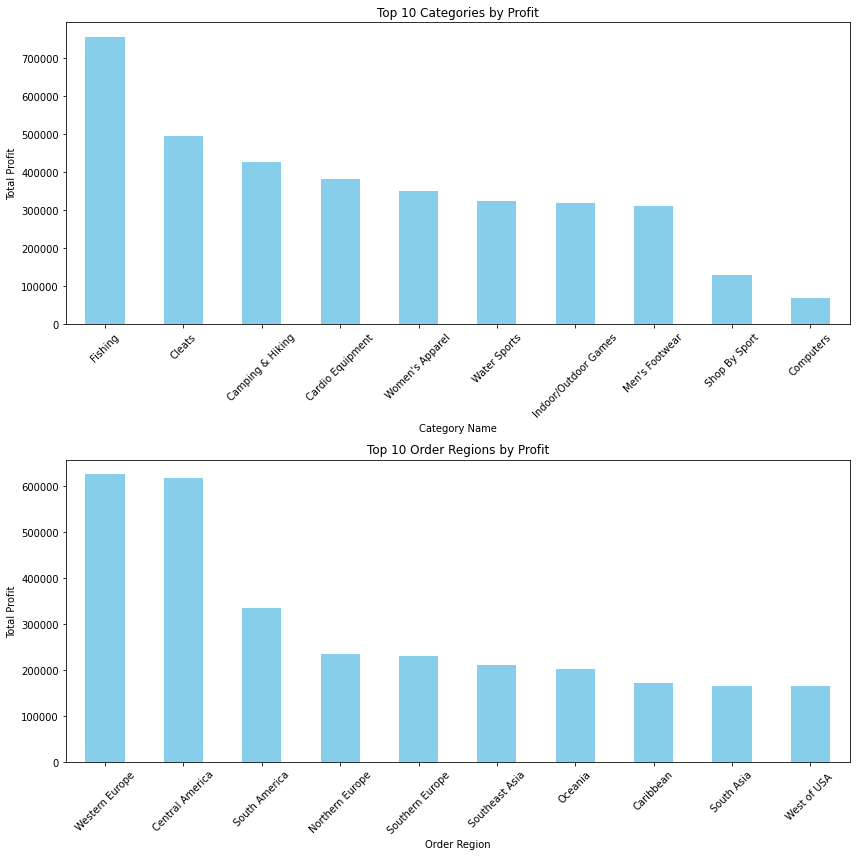

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming DataCo is your DataFrame
# Group by Category Name and sum the Profit
category_profit = DataCo.groupby('Category Name')['Order Profit Per Order'].sum()

# Get top 10 categories by profit
top_10_categories = category_profit.nlargest(10)

# Group by Order Region and sum the Profit
region_profit = DataCo.groupby('Order Region')['Order Profit Per Order'].sum()

# Get top 10 order regions by profit
top_10_regions = region_profit.nlargest(10)

# Set up the figure and axes
fig, axes = plt.subplots(2, 1, figsize=(12, 12))  # Two subplots in one figure

# Plotting the top 10 categories by profit
top_10_categories.plot(kind='bar', color='skyblue', ax=axes[0])
axes[0].set_xlabel('Category Name')
axes[0].set_ylabel('Total Profit')
axes[0].set_title('Top 10 Categories by Profit')
axes[0].tick_params(axis='x', rotation=45)

# Plotting the top 10 order regions by profit
top_10_regions.plot(kind='bar', color='skyblue', ax=axes[1])
axes[1].set_xlabel('Order Region')
axes[1].set_ylabel('Total Profit')
axes[1].set_title('Top 10 Order Regions by Profit')
axes[1].tick_params(axis='x', rotation=45)

# Adjust layout
plt.tight_layout()

# Save the figure
plt.savefig('Top_10_Profit_Analysis.png', bbox_inches='tight')

# Show the plot
plt.show()


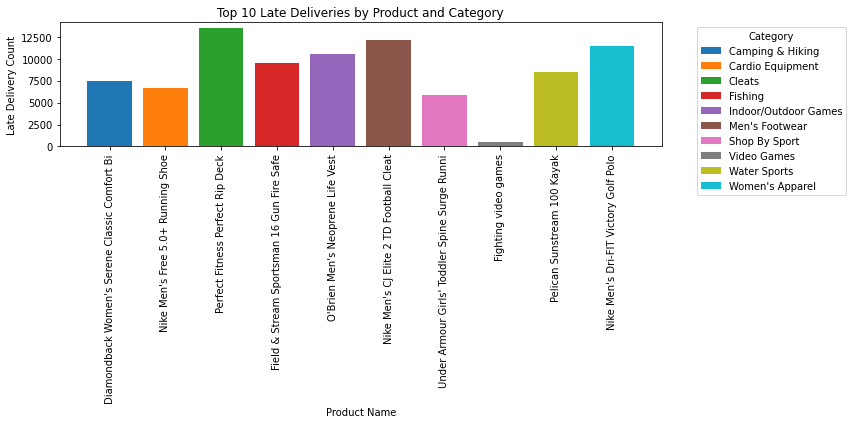

In [57]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming DataCo is your DataFrame
# Filter for late deliveries (assuming Late_delivery_risk = 1 indicates late delivery)
late_deliveries = DataCo[DataCo['Late_delivery_risk'] == 1]

# Group by Category Name and count the late deliveries by product
category_product_late = late_deliveries.groupby(['Category Name', 'Product Name']).size().reset_index(name='Late Delivery Count')

# Get top 10 late deliveries by product
top_10_product_late = category_product_late.sort_values(by='Late Delivery Count', ascending=False).head(10)

# Plotting the bar chart
plt.figure(figsize=(12, 6))
for category, group in top_10_product_late.groupby('Category Name'):
    plt.bar(group['Product Name'], group['Late Delivery Count'], label=category)
plt.xlabel('Product Name')
plt.ylabel('Late Delivery Count')
plt.title('Top 10 Late Deliveries by Product and Category')
plt.xticks(rotation=90)
plt.legend(title='Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


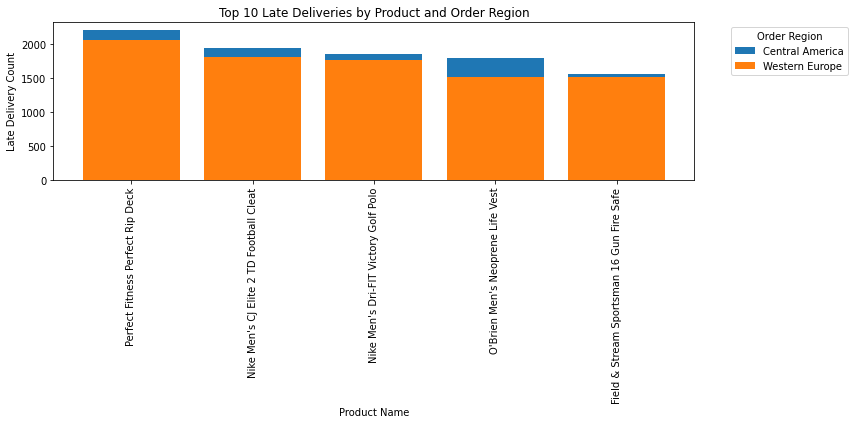

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming DataCo is your DataFrame
# Filter for late deliveries (assuming Late_delivery_risk = 1 indicates late delivery)
late_deliveries = DataCo[DataCo['Late_delivery_risk'] == 1]

# Group by Order Region and count the late deliveries by product
region_product_late = late_deliveries.groupby(['Order Region', 'Product Name']).size().reset_index(name='Late Delivery Count')

# Get top 10 late deliveries by product
top_10_product_late = region_product_late.sort_values(by='Late Delivery Count', ascending=False).head(10)

# Plotting the bar chart
plt.figure(figsize=(12, 6))
for region, group in top_10_product_late.groupby('Order Region'):
    plt.bar(group['Product Name'], group['Late Delivery Count'], label=region)
plt.xlabel('Product Name')
plt.ylabel('Late Delivery Count')
plt.title('Top 10 Late Deliveries by Product and Order Region')
plt.xticks(rotation=90)
plt.legend(title='Order Region', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


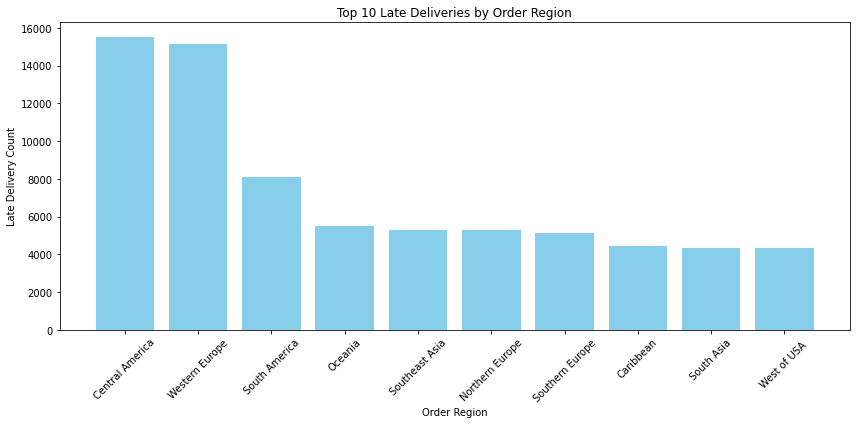

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming DataCo is your DataFrame
# Filter for late deliveries (assuming Late_delivery_risk = 1 indicates late delivery)
late_deliveries = DataCo[DataCo['Late_delivery_risk'] == 1]

# Group by Order Region and count the late deliveries
region_late_count = late_deliveries.groupby('Order Region').size().reset_index(name='Late Delivery Count')

# Get top 10 order regions by late deliveries
top_10_regions = region_late_count.sort_values(by='Late Delivery Count', ascending=False).head(10)

# Plotting the bar chart
plt.figure(figsize=(12, 6))
plt.bar(top_10_regions['Order Region'], top_10_regions['Late Delivery Count'], color='skyblue')
plt.xlabel('Order Region')
plt.ylabel('Late Delivery Count')
plt.title('Top 10 Late Deliveries by Order Region')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


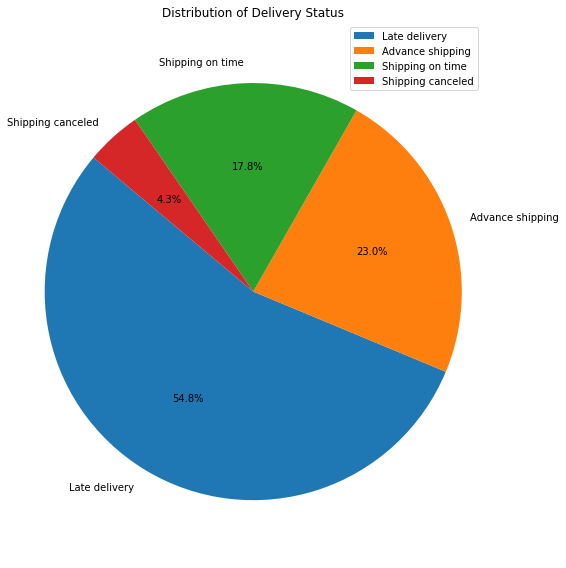

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming DataCo is your DataFrame
# Count the occurrences of each Delivery Status
delivery_status_counts = DataCo['Delivery Status'].value_counts()

# Plotting the pie chart
plt.figure(figsize=(8, 8))
plt.pie(delivery_status_counts, labels=delivery_status_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Distribution of Delivery Status')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

# Adding a legend
plt.legend(loc='upper right', labels=delivery_status_counts.index)
plt.tight_layout()
plt.savefig('Delivery Status.png', bbox_inches='tight')  # Save the figure as an image

plt.show()


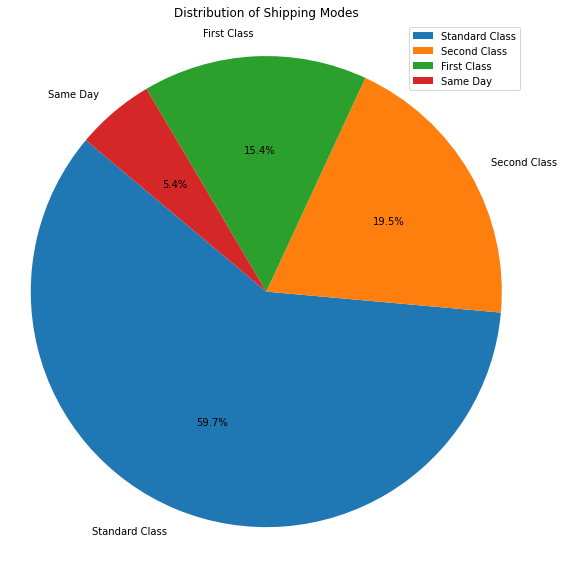

In [35]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming DataCo is your DataFrame
# Count the occurrences of each Shipping Mode
shipping_mode_counts = DataCo['Shipping Mode'].value_counts()

# Plotting the pie chart
plt.figure(figsize=(8, 8))
plt.pie(shipping_mode_counts, labels=shipping_mode_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Distribution of Shipping Modes')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

# Adding a legend
plt.legend(loc='upper right', labels=shipping_mode_counts.index)
plt.tight_layout()
plt.savefig('Distribution of shipping mode .png', bbox_inches='tight')  # Save the figure as an image

plt.show()


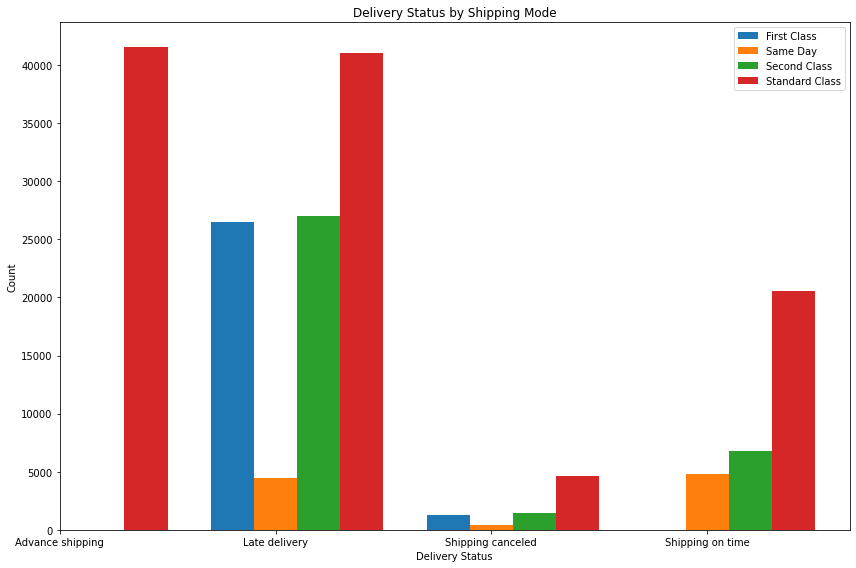

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Assuming DataCo is your DataFrame
# Group by Delivery Status and Shipping Mode, count occurrences
status_shipping_counts = DataCo.groupby(['Delivery Status', 'Shipping Mode']).size().unstack()

# Plotting the grouped bar chart
plt.figure(figsize=(12, 8))

# Define the number of bars
num_bars = len(status_shipping_counts.index)
bar_width = 0.2
index = np.arange(num_bars)

# Plot each group
for i, status in enumerate(status_shipping_counts.columns):
    plt.bar(index + i * bar_width, status_shipping_counts[status], width=bar_width, label=status)

plt.xlabel('Delivery Status')
plt.ylabel('Count')
plt.title('Delivery Status by Shipping Mode')
plt.xticks(index + bar_width, status_shipping_counts.index)
plt.legend()
plt.tight_layout()
plt.savefig('Delivery Status By Shipping Mode .png', bbox_inches='tight')  # Save the figure as an image

plt.show()


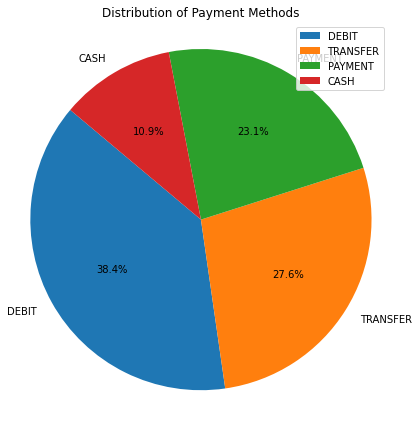

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming DataCo is your DataFrame
# Count the occurrences of each Payment Method
payment_method_counts = DataCo['Type'].value_counts()

# Plotting the pie chart
plt.figure(figsize=(6, 6))
plt.pie(payment_method_counts, labels=payment_method_counts.index, autopct='%1.1f%%', startangle=140)
plt.title('Distribution of Payment Methods')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.

# Adding a legend
plt.legend(loc='upper right', labels=payment_method_counts.index)
plt.tight_layout()
plt.savefig('Payment Method.png', bbox_inches='tight')  # Save the figure as an image

plt.show()


### OLS Regression

In [23]:
reg_SC = SCData.copy()

In [24]:
le = preprocessing.LabelEncoder()# create the Labelencoder object
reg_SC['market']= le.fit_transform(reg_SC['market'])#convert the categorical columns into numeric
reg_SC['type']= le.fit_transform(reg_SC['type'])
reg_SC['product_name']= le.fit_transform(reg_SC['product_name'])
reg_SC['customer_segment']= le.fit_transform(reg_SC['customer_segment'])
reg_SC['order_region']= le.fit_transform(reg_SC['order_region'])
reg_SC['category_name']= le.fit_transform(reg_SC['category_name'])
reg_SC['shipping_mode']= le.fit_transform(reg_SC['shipping_mode'])
reg_SC['delivery_status']= le.fit_transform(reg_SC['delivery_status'])
reg_SC['customer_country']  = le.fit_transform(reg_SC['customer_country'])
reg_SC['customer_state']= le.fit_transform(reg_SC['customer_state'])
reg_SC['order_city'] = le.fit_transform(reg_SC['order_city'])
reg_SC['customer_city']= le.fit_transform(reg_SC['customer_city'])
reg_SC['department_name']= le.fit_transform(reg_SC['department_name'])
reg_SC['order_state'] = le.fit_transform(reg_SC['order_state'])
reg_SC['order_status'] = le.fit_transform(reg_SC['order_status'])
reg_SC['order_country']= le.fit_transform(reg_SC['order_country'])

In [25]:
reg_SC['Intercept'] = 1

In [54]:
independants=reg_SC[['Intercept',
       'order_item_product_price','order_country','order_item_discount',
      'order_profit_per_order','order_item_quantity','delivery_status','customer_country','customer_state','order_city','customer_city','department_name','order_state','order_status',
'market','type','product_name','customer_segment','order_region','category_name','shipping_mode']]
ols_model = sm.OLS(reg_SC['order_item_total'], independants)
results = ols_model.fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:       order_item_total   R-squared:                       0.920
Model:                            OLS   Adj. R-squared:                  0.920
Method:                 Least Squares   F-statistic:                 1.043e+05
Date:                Mon, 12 Aug 2024   Prob (F-statistic):               0.00
Time:                        07:42:01   Log-Likelihood:            -8.9208e+05
No. Observations:              180519   AIC:                         1.784e+06
Df Residuals:                  180498   BIC:                         1.784e+06
Df Model:                          20                                         
Covariance Type:            nonrobust                                         
============================================================================================
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                  -35.4732      0.637    -55.714      0.000     -36.721     -34.225
order_item_product_price     0.9688      0.001   1070.831      0.000       0.967       0.971
order_country               -0.0022      0.002     -1.075      0.282      -0.006       0.002
order_item_discount         -0.6025      0.005   -132.234      0.000      -0.611      -0.594
order_profit_per_order       0.0120      0.001     15.571      0.000       0.010       0.013
order_item_quantity         53.7354      0.071    751.562      0.000      53.595      53.876
delivery_status              0.0821      0.082      1.001      0.317      -0.079       0.243
customer_country             0.0980      0.231      0.423      0.672      -0.356       0.552
customer_state               0.0065      0.008      0.846      0.397      -0.009       0.021
order_city                4.667e-05   8.22e-05      0.568      0.570      -0.000       0.000
customer_city                0.0009      0.001      1.541      0.123      -0.000       0.002
department_name             -1.2469      0.034    -36.701      0.000      -1.313      -1.180
order_state              -9.184e-05      0.000     -0.338      0.735      -0.001       0.000
order_status                -0.0678      0.060     -1.135      0.256      -0.185       0.049
market                      -0.4648      0.071     -6.502      0.000      -0.605      -0.325
type                         0.0599      0.136      0.441      0.659      -0.206       0.326
product_name                 0.0320      0.004      7.565      0.000       0.024       0.040
customer_segment            -0.0677      0.105     -0.647      0.517      -0.273       0.137
order_region                -0.0057      0.012     -0.472      0.637      -0.029       0.018
category_name               -0.6523      0.006   -105.529      0.000      -0.664      -0.640
shipping_mode                0.0607      0.073      0.835      0.404      -0.082       0.203
==============================================================================
Omnibus:                    70854.355   Durbin-Watson:                   0.975
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           845376.317
Skew:                           1.554   Prob(JB):                         0.00
Kurtosis:                      13.136   Cond. No.                     1.74e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.74e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [27]:
train_SC = SCData.copy()

In [55]:
le = preprocessing.LabelEncoder()# create the Labelencoder object
train_SC['customer_country']  = le.fit_transform(train_SC['customer_country'])#convert the categorical columns into numeric
train_SC['market']= le.fit_transform(train_SC['market'])
train_SC['delivery_status']= le.fit_transform(train_SC['delivery_status'])
train_SC['type']= le.fit_transform(train_SC['type'])
train_SC['product_name']= le.fit_transform(train_SC['product_name'])
train_SC['customer_segment']= le.fit_transform(train_SC['customer_segment'])
train_SC['customer_state']= le.fit_transform(train_SC['customer_state'])
train_SC['order_region']= le.fit_transform(train_SC['order_region'])
train_SC['order_city'] = le.fit_transform(train_SC['order_city'])
train_SC['category_name']= le.fit_transform(train_SC['category_name'])
train_SC['customer_city']= le.fit_transform(train_SC['customer_city'])
train_SC['department_name']= le.fit_transform(train_SC['department_name'])
train_SC['order_state'] = le.fit_transform(train_SC['order_state'])
train_SC['order_status'] = le.fit_transform(train_SC['order_status'])
train_SC['shipping_mode']= le.fit_transform(train_SC['shipping_mode'])
train_SC['order_country']= le.fit_transform(train_SC['order_country'])


train_SCData=train_SC.drop(['shipping_date_dateorders','order_date_dateorders'],axis=1)

xorderitemquantity=train_SCData .loc[:, train_SCData .columns !='order_item_quantity']
yorderitemquantity=train_SCData['order_item_quantity']
xorderitemquantity_train, xorderitemquantity_test,yorderitemquantity_train,yorderitemquantity_test = train_test_split(xorderitemquantity,yorderitemquantity,test_size = 0.3, random_state = 42)


scaler=MinMaxScaler()
xorderitemquantity_train=scaler.fit_transform(xorderitemquantity_train)
xorderitemquantity_test=scaler.transform(xorderitemquantity_test)


Linear Regression

In [33]:
model_orderitemquantity=LinearRegression()
regressionmodel(model_orderitemquantity,xorderitemquantity_train, xorderitemquantity_test,yorderitemquantity_train,yorderitemquantity_test)

Model parameter used are: LinearRegression()
MAE of Total amount per order is         : 0.33908849785509737
RMSE of Total amount per order is        : 0.5253875506211831


RandomForestRegressor

In [34]:
model_orderitemquantity = RandomForestRegressor(n_estimators=100,max_depth=10, random_state=40)
regressionmodel(model_orderitemquantity,xorderitemquantity_train, xorderitemquantity_test,yorderitemquantity_train,yorderitemquantity_test)

Model parameter used are: RandomForestRegressor(max_depth=10, random_state=40)
MAE of Total amount per order is         : 7.201418125415458e-05
RMSE of Total amount per order is        : 0.005801260843366288


Regression model evaluation

In [62]:
Regression_data = {'Regression Model':  ['Linear Regression','Random Forest'],
        'MAE' :        [ 0.33908849785509737,7.201418125415458],
        'RMSE':        [ 0.5253875506211831,0.005801260843366288]}
Regression_comparision = pd.DataFrame (Regression_data, columns = ['Regression Model','MAE','RMSE'])
Regression_comparision

,Regression Model,MAE,RMSE
0,Linear Regression,0.339088,0.525388
1,Random Forest,7.201418,0.005801


Classification Model

In [57]:
train_DataSC = SCData.copy()
train_DataSC['late_delivery']=np.where(train_DataSC['delivery_status'] == 'Late delivery', 1, 0) 
train_dataSC=train_DataSC.drop(['delivery_status','late_delivery_risk'], axis=1)
le = preprocessing.LabelEncoder()# create the Labelencoder object
train_dataSC['customer_country']  = le.fit_transform(train_dataSC['customer_country'])#convert the categorical columns into numeric
train_dataSC['market']= le.fit_transform(train_dataSC['market'])
train_dataSC['type']= le.fit_transform(train_dataSC['type'])
train_dataSC['product_name']= le.fit_transform(train_dataSC['product_name'])
train_dataSC['customer_segment']= le.fit_transform(train_dataSC['customer_segment'])
train_dataSC['customer_state']= le.fit_transform(train_dataSC['customer_state'])
train_dataSC['order_region']= le.fit_transform(train_dataSC['order_region'])
train_dataSC['order_city'] = le.fit_transform(train_dataSC['order_city'])
train_dataSC['category_name']= le.fit_transform(train_dataSC['category_name'])
train_dataSC['customer_city']= le.fit_transform(train_dataSC['customer_city'])
train_dataSC['department_name']= le.fit_transform(train_dataSC['department_name'])
train_dataSC['order_state'] = le.fit_transform(train_dataSC['order_state'])
train_dataSC['order_status'] = le.fit_transform(train_dataSC['order_status'])
train_dataSC['shipping_mode']= le.fit_transform(train_dataSC['shipping_mode'])
train_dataSC['order_country']= le.fit_transform(train_dataSC['order_country'])

In [58]:
train_dataSCM=train_dataSC.drop(['shipping_date_dateorders','order_date_dateorders'],axis=1)

xlatedelivery=train_dataSCM .loc[:, train_dataSCM .columns != 'late_delivery']
ylatedelivery=train_dataSCM['late_delivery']
xlatedelivery_train, xlatedelivery_test,ylatedelivery_train,ylatedelivery_test = train_test_split(xlatedelivery,ylatedelivery,test_size = 0.3, random_state = 42)

sc = StandardScaler()
xlatedelivery_train=sc.fit_transform(xlatedelivery_train)
xlatedelivery_test=sc.transform(xlatedelivery_test)

In [41]:
def classifiermodel(model_latedelivery,xlatedelivery_train, xlatedelivery_test,ylatedelivery_train,ylatedelivery_test):
    model_latedelivery=model_latedelivery.fit(xlatedelivery_train,ylatedelivery_train) # Fitting train data for predection of late delivery
    ylatedelivery_pred=model_latedelivery.predict(xlatedelivery_test)  
    accuracy_latedelivery=accuracy_score(ylatedelivery_pred, ylatedelivery_test) #Accuracy for predection of late delivery
    recall_latedelivery=recall_score(ylatedelivery_pred, ylatedelivery_test)# Recall score for predection of late delivery
    conf_latedelivery=confusion_matrix(ylatedelivery_test, ylatedelivery_pred)#predection of late delivery
    f1_latedelivery=f1_score(ylatedelivery_test, ylatedelivery_pred)#predection of late delivery
    print('Model paramters used are :',model_latedelivery)
    print('Accuracy of late delivery status is:', (accuracy_latedelivery)*100,'%')
    print('Recall score of late delivery status is:', (recall_latedelivery)*100,'%')
    print('F1 score of late delivery status is:', (f1_latedelivery)*100,'%')
    print('Conf Matrix of late delivery status is: \n',(conf_latedelivery))

Random Forest

In [59]:
model_latedelivery = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=0)
classifiermodel(model_latedelivery,xlatedelivery_train, xlatedelivery_test,ylatedelivery_train,ylatedelivery_test)

Model paramters used are : RandomForestClassifier(max_depth=10, random_state=0)
Accuracy of late delivery status is: 99.86889725976808 %
Recall score of late delivery status is: 99.76187281996243 %
F1 score of late delivery status is: 99.88079447960915 %
Conf Matrix of late delivery status is: 
 [[24340    71]
 [    0 29745]]


SVM

In [43]:
model_latedelivery = svm.LinearSVC()
classifiermodel(model_latedelivery,xlatedelivery_train, xlatedelivery_test,ylatedelivery_train,ylatedelivery_test)

Model paramters used are : LinearSVC()
Accuracy of late delivery status is: 98.2550409926878 %
Recall score of late delivery status is: 96.93305521152467 %
F1 score of late delivery status is: 98.43612954473993 %
Conf Matrix of late delivery status is: 
 [[23470   941]
 [    4 29741]]


Logistic Classification

In [44]:
model_latedelivery = LogisticRegression(solver='lbfgs',random_state=0) 
classifiermodel(model_latedelivery,xlatedelivery_train, xlatedelivery_test,ylatedelivery_train,ylatedelivery_test)

Model paramters used are : LogisticRegression(random_state=0)
Accuracy of late delivery status is: 98.25319447521974 %
Recall score of late delivery status is: 96.93295524917701 %
F1 score of late delivery status is: 98.43444874722802 %
Conf Matrix of late delivery status is: 
 [[23470   941]
 [    5 29740]]


Linear Discriminant Analysis

In [45]:
model_latedelivery = LinearDiscriminantAnalysis()
classifiermodel(model_latedelivery,xlatedelivery_train, xlatedelivery_test,ylatedelivery_train,ylatedelivery_test)

Model paramters used are : LinearDiscriminantAnalysis()
Accuracy of late delivery status is: 96.18509491099786 %
Recall score of late delivery status is: 96.26274444258733 %
F1 score of late delivery status is: 96.53704324505532 %
Conf Matrix of late delivery status is: 
 [[23293  1118]
 [  948 28797]]


Gaussian Naive Bayes Model

In [46]:
model_latedelivery = GaussianNB()
classifiermodel(model_latedelivery,xlatedelivery_train, xlatedelivery_test,ylatedelivery_train,ylatedelivery_test)

Model paramters used are : GaussianNB()
Accuracy of late delivery status is: 85.03212940394415 %
Recall score of late delivery status is: 88.0338875804127 %
F1 score of late delivery status is: 86.07025020621391 %
Conf Matrix of late delivery status is: 
 [[21007  3404]
 [ 4702 25043]]


Classification model evaluation

In [60]:
Classification_data = {'Classification Model':  ['Random Forest Classification','Support Vector Machines','Logistic Classification Model',
                                 'Linear Discriminant Analysis','Gaussian Naive Bayes Model'],
       'Accuracy' :        [ 99.86889725976808, 98.2550409926878,98.25319447521974,96.18509491099786, 85.03212940394415],
        'Recall':        [99.76187281996243, 96.93305521152467,96.93295524917701,96.26274444258733,88.0338875804127],
        'F1' :     [99.88079447960915,98.43612954473993,98.43444874722802,96.53704324505532,86.07025020621391],   
        'TN' :        [24340,23470,23470,23293,21007],
        'FP':        [71, 941,941,1118,3404],
        'FN' :     [0,4,5,948,4702],
        'TP':     [29745,29741,29740,28797,25043] }
Classification_comparision = pd.DataFrame (Classification_data, columns = ['Classification Model','Accuracy','Recall','F1','TN','FP',
        'FN','TP'])
Classification_comparision 

,Classification Model,Accuracy,Recall,F1,TN,FP,FN,TP
0,Random Forest Classification,99.868897,99.761873,99.880794,24340,71,0,29745
1,Support Vector Machines,98.255041,96.933055,98.436130,23470,941,4,29741
2,Logistic Classification Model,98.253194,96.932955,98.434449,23470,941,5,29740
3,Linear Discriminant Analysis,96.185095,96.262744,96.537043,23293,1118,948,28797
4,Gaussian Naive Bayes Model,85.032129,88.033888,86.070250,21007,3404,4702,25043
